A notebook to validate the results of VRDR Resampling to CaSSIS

In [178]:
# auto reload
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [179]:
from affine import Affine
import arosics
import astropy.units as u
import geoarray as ga
from matplotlib import pyplot as plt
import numpy as np
from pathlib import Path
import pdr
import pvl
from pyproj import CRS
import rioxarray
import xarray as xr

# Overview
- Load a CaRDR example tile
- Load an overlapping CaSSIS cube
- Load the accompanying VRDR DDR (vrrde cube)
- Get surface slope from the DDR
- Get the Solar Incidence of the CaSSIS cube
- Rescale the CaRDR tile for the CaSSIS comparison observation
- Co-align the CaSSIS cube and CaRDR tile
- downsample the CaSSIS cube to the CaRDR resolution
- show statistics on the differences for each channel
- check on other CaSSIS cubes.
  - check for near-equatorial regions and high latitude regions
  - check for 
    - low topographic variation, low colour variation
    - high topographic variation, low colour variation
    - low topographic variation, high colour variation
    - high topographic variation, high colour variation

# Overview

- Load a CaRDR Tile
- Load the CaRDR Browse Products
- Load the VRDR Tile Browse Products
- Compare the CaRDR and VRDR tiles

# Set out the figure output directory

In [180]:
out_dir = Path('.', 'cardr_checks')
out_dir.mkdir(exist_ok=True)

# Load a CaRDR Tile

Let's load the t1250 CaRDR tile, and then load the source VRDR tile browse products for comparison.

In [181]:
# todo: code to access and download the data from the public repository

In [182]:
cardr_tile_path = Path("./demo_data/cardr/mc13/t1250/t1250_cifcub_20n078_0654_1.tif")
# check exists
assert cardr_tile_path.exists(), f"Cardr tile not found at {cardr_tile_path}"

Let's read this geotiff into Python.

In [183]:
def clip_and_normalise(da, percent=1.0):
    """Clip and normalise each band independently using percentile stretch."""
    bands = []

    percentiles = (percent, 100 - percent)
    for b in da.band.values:
        band = da.sel(band=b).astype(float)
        low, high = np.nanpercentile(band.values, percentiles)
        stretched = (band.clip(low, high) - low) / (high - low)
        bands.append(stretched)
    return xr.concat(bands, dim="band")

In [184]:
cardr_tile_path = Path("./demo_data/cardr/mc13/t1250")
# check exists
assert cardr_tile_path.exists(), f"Cardr tile not found at {cardr_tile_path}"

In [186]:
cifcub_path  = next(cardr_tile_path.glob("*cifcub*.tif"))
assert cifcub_path, f"No cifcub file found in {cardr_tile_path}"
print(cifcub_path)

demo_data/cardr/mc13/t1250/t1250_cifcub_20n078_0654_1.tif


In [ ]:
class CaRDRTileReader:
    """A helper function for reading CaRDR tile data in rioxarray
    data structures, that parse georeferencing information from the
    data geotiffs
    """    

    def __init__(self, 
                tile_path):

        self.tile_path = tile_path

        # load the Lambert Albedo Cube 'cifcub'
        self.cifcub_path  = next(self.tile_path.glob("*cifcub*.tif"))
        assert self.cifcub_path, f"No cifcub file found in {self.tile_path}"
        self.ds = self.load_cifcub(self.cifcub_path).to_dataset(name="cifcub")

        # load the spectral parameter cube 'cspcub'
        self.cspcub_path  = next(self.tile_path.glob("*cspcub*.tif"))
        assert self.cspcub_path, f"No cspcub file found in {self.tile_path}"
        self.cspcub = self.load_cspcub(self.cspcub_path)

        # get CRS info
        self.crs = CRS.from_wkt(self.ds.cifcub.rio.crs.to_wkt())
        self.geo_crs = self.ds.cifcub.rio.crs.from_wkt(self.crs.geodetic_crs.to_wkt())

    def load_cifcub(self, path):
        """Load the CaRDR CIFCUB as a DataArray with correct coordinates and 
        metadata."""

        cifcub_da = rioxarray.open_rasterio(path)
        # Load the envi hdr to get metadata
        hdr = self.hdr_parser(path)

        # extract the mapping and band info dicts
        mapping_dict_keys = {'map info', 'projection info', 'coordinate system string', 'x start', 'y start'}
        mapping_dict = {k: hdr[k] for k in mapping_dict_keys}
        band_dict_keys = {'bands', 'band names', 'wavelength', 'wavelength units'}
        band_dict = {k: hdr[k] for k in band_dict_keys}

        # update the coordinates with the band names and wavelengths
        cifcub_da = cifcub_da.assign_coords(
            band=band_dict['band names'],
            cwl= ("band", band_dict['wavelength'])
        )

        # unit parsing
        cwl_unit = band_dict['wavelength units']
        if cwl_unit.endswith('s'):
            cwl_unit = cwl_unit[:-1]
        cifcub_da.cwl.attrs['units'] = str(u.Unit(cwl_unit))

        # update the long name to the units
        cifcub_da.attrs['long_name'] = 'Lambert Albedo'
        cifcub_da.attrs['units'] = str(u.dimensionless_unscaled)

        return cifcub_da
    
    def load_cspcub(self, path):
        """Load the CaRDR CSPCUB as a DataArray with correct coordinates and 
        metadata."""

        cspcub_da = rioxarray.open_rasterio(path)
        # Load the envi hdr to get metadata
        hdr = self.hdr_parser(path)

        # extract the mapping and band info dicts
        mapping_dict_keys = {'map info', 'projection info', 'coordinate system string', 'x start', 'y start'}
        mapping_dict = {k: hdr[k] for k in mapping_dict_keys}
        product_dict_keys = {'bands', 'band names', 'wavelength', 'wavelength units'}
        product_dict = {k: hdr[k] for k in product_dict_keys}

        # update the coordinates with the product names
        cspcub_da = cspcub_da.assign_coords(
            product=product_dict['band names']
        )

        # update the long name to the units
        cspcub_da.attrs['long_name'] = 'Spectral Parameter'
        cspcub_da.attrs['units'] = str(u.dimensionless_unscaled)

        return cspcub_da

    @staticmethod
    def hdr_parser(img_path: Path) -> dict:
        """Parse the CaRDR ENVI .hdr file to dict,
        with correctly typed values.
        """

        # inner helper functions
        def try_cast(value: str):
            """Try to cast a string to int, then float, else keep as str."""
            value = value.strip()
            try:
                return int(value)
            except ValueError:
                pass
            try:
                return float(value)
            except ValueError:
                pass
            return value

        def parse_value(raw: str):
            raw = raw.strip()

            # Brace-delimited list: { item, item, ... }
            if raw.startswith("{") and raw.endswith("}"):
                inner = raw[1:-1]
                # Split on commas, but not commas inside nested brackets/quotes
                items = [item.strip() for item in inner.split(",")]
                return [try_cast(item) for item in items]

            return try_cast(raw)

        # set hdr filepath
        filepath = img_path.with_suffix(".hdr")

        # read the file lines
        with open(filepath, "r", encoding="utf-8") as f:
            lines = f.read().splitlines()

        # parse to hdr dict
        hdr = {}

        # skip the "ENVI" header line
        i = 0
        if lines and lines[0].strip() == "ENVI":
            hdr["_format"] = "ENVI"
            i = 1

        # handle multi-line brace blocks
        joined_lines = []
        while i < len(lines):
            line = lines[i]
            # Accumulate lines until braces are balanced
            while line.count("{") > line.count("}") and i + 1 < len(lines):
                i += 1
                line += " " + lines[i].strip()
            joined_lines.append(line)
            i += 1

        for line in joined_lines:
            line = line.strip()
            if not line or "=" not in line:
                continue

            key, _, raw_value = line.partition("=")
            key = key.strip()
            hdr[key] = parse_value(raw_value.strip())

        return hdr
    
    def stretch_cube(self, percent=1.0):
        """Add a new DataArray to the DataSet with the bands independently 
        clipped and normalised using percentile stretch."""
        
        stretch_da = clip_and_normalise(self.da, percent=percent)        
    
    # # visualisation helper functions
    def show_false_colour(self, bands: List[str,str,str]=['NIR','PAN','BLU'], percent=1.0, geo_crs: bool=True, **kwargs):
        """Display a stretched false colour image from the given bands

        :param bands: List of band names to use for the RGB channels, defaults to ['NIR','PAN','BLU']
        :type bands: list, optional
        :param percent: Percentile for clipping and normalisation, defaults to 1.0
        :type percent: float, optional
        :param geo_crs: Whether to reproject to the geographic CRS, defaults to True
        :type geo_crs: bool, optional
        """        
        rgb = self.da.sel(band=bands)
        
        if geo_crs:
            rgb = rgb.rio.reproject(self.geo_crs)
        
        rgb = clip_and_normalise(rgb, percent=percent)

        # show the plot
        rgb.plot.imshow(rgb="band", **kwargs)

        # update title
        plt.title(f"False colour RGB: {bands} ({percent}% stretch)")

        plt.gca().set_aspect('equal', adjustable='box')

In [161]:
cardr_tile = CaRDRTileReader(cardr_tile_path)

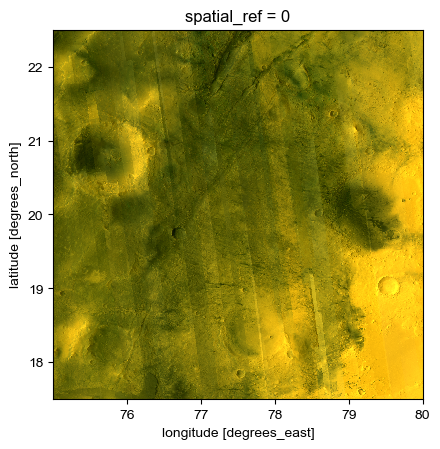

In [175]:
cardr_tile.da.rio.reproject(cardr_tile.geo_crs).sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(rgb="band", robust=True)
plt.gca().set_aspect('equal', adjustable='box')

# Load the Source VRDR Tile for Comparison

In [ ]:
# todo: code to access and download the data from PDS

In [ ]:
vrdr_dir_path = Path("./demo_data/crism/vrdr/mc13/t1250")

# Reading the VRDR Derived Data to get slope angles

Our goal is to rescale the CaRDR Lambert Albedo tile to units of Radiance Factor, by using the surface slope normal and the Solar incidence of the CaSSIS observation.

To do this, we need to access the DDR product cube associated with the CaRDR file, from the VRDR dataset.

In [12]:
# todo: replace with link to dataportal repository
vrdr_de_lbl_path = Path("./demo_data/crism/vrdr/t1250_vrrde_20n078_0654_1.lbl")

The band of interest are:
1. INA at areoid - deg [4]
2. EMA at areoid - deg [5]
3. Phase angle - deg [6]
4. INA at surface [9]
5. EMA at surface [10]
6. Slope amgnitude from MOLA - deg [11]
7. MOLA slope azimuth - deg clckwise from N [12]
8. Elevation - meters relative to MOLA [13]

In [13]:
class VRDRDETileReader:
    
    def __init__(self, lbl_path, cardr_tile):
        self.lbl_path = lbl_path
        
        loader = pdr.read(lbl_path)

        band_labels = loader.metaget('BAND_NAME')

        loader.load('IMAGE', reload=True)
        de_np = loader.IMAGE

        self.da = xr.DataArray(
            de_np,
            dims=("meta_band", "y", "x"),
            coords={
                "y": cardr_tile.da.y,
                "x": cardr_tile.da.x,
                "meta_band": list(band_labels)
            },
            name="metadata"
        )

        self.da = self.da.rio.write_crs(cardr_tile.da.rio.crs)
        self.da = self.da.rio.write_transform(cardr_tile.da.rio.transform())

        # convert to a dataset for easier access to the metadata fields
        self.ds = self.da.to_dataset(dim="meta_band")

In [14]:
ddr = VRDRDETileReader(vrdr_de_lbl_path, cardr_tile)

Let;s have a look at some of these metadata bands.

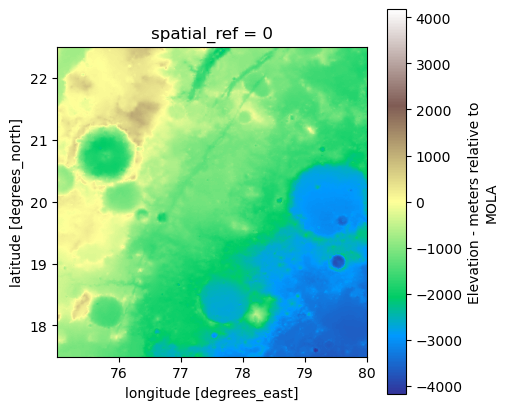

In [15]:
ddr.ds['Elevation - meters relative to MOLA'].rio.reproject(cardr_tile.geo_crs).plot(cmap='terrain',figsize=(5, 5))
plt.gca().set_aspect('equal', adjustable='box')

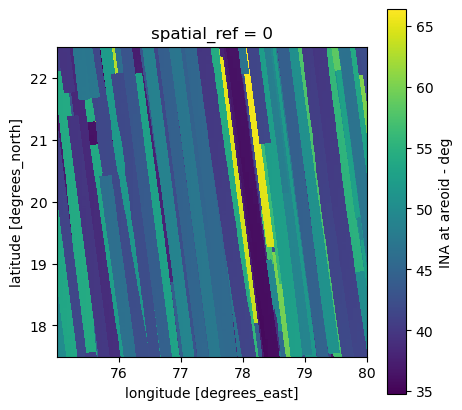

In [16]:
ddr.ds['INA at areoid - deg'].rio.reproject(cardr_tile.geo_crs).plot(figsize=(5,5))
plt.gca().set_aspect('equal', adjustable='box')

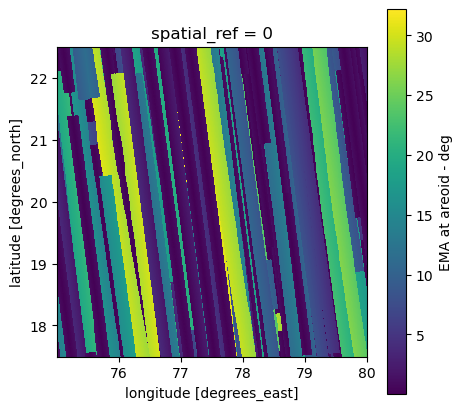

In [17]:
ddr.ds['EMA at areoid - deg'].rio.reproject(cardr_tile.geo_crs).plot(figsize=(5,5))
plt.gca().set_aspect('equal', adjustable='box')

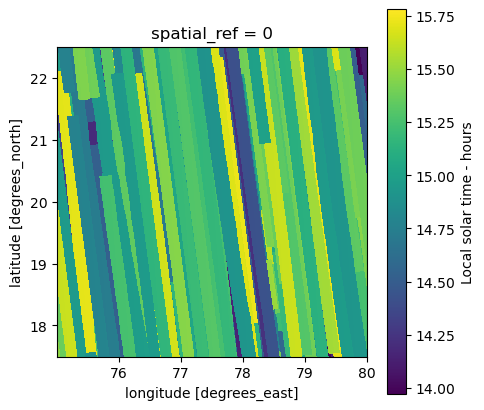

In [18]:
ddr.ds['Local solar time - hours'].rio.reproject(cardr_tile.geo_crs).plot(figsize=(5,5))
plt.gca().set_aspect('equal', adjustable='box')

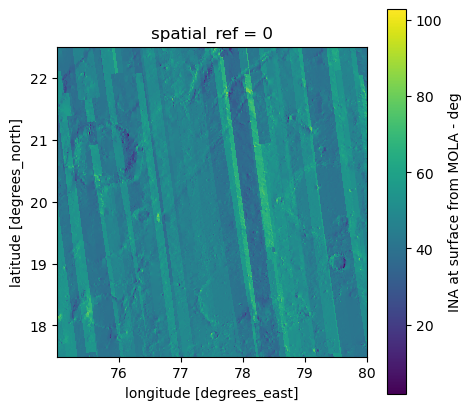

In [19]:
ddr.ds['INA at surface from MOLA - deg'].rio.reproject(cardr_tile.geo_crs).plot(figsize=(5, 5))
plt.gca().set_aspect('equal', adjustable='box')

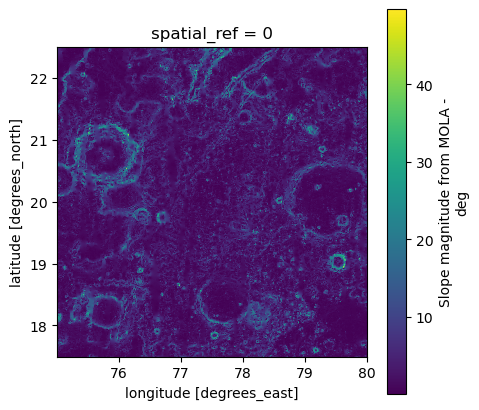

In [20]:
ddr.ds['Slope magnitude from MOLA - deg'].rio.reproject(cardr_tile.geo_crs).plot(figsize=(5, 5))
plt.gca().set_aspect('equal', adjustable='box')

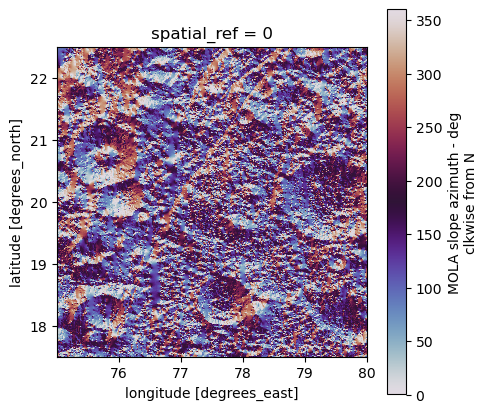

In [21]:
ddr.ds['MOLA slope azimuth - deg clkwise from N'].rio.reproject(cardr_tile.geo_crs).plot(cmap='twilight', figsize=(5, 5))
plt.gca().set_aspect('equal', adjustable='box')

# Reading the CaSSIS Cube

Now let's read in the CaSSIS cube: MY37_024813_159

In [23]:
cassis_cub_path = Path("./demo_data/cassis/MY37_024813_159/cubes/MY37_024813_159_0.cubeit.cub")

In [24]:
cassis_cub_path.exists()

True

There's not a particualrly neat way of reading in the CaSSIS data into an xarray, so let's develop this as a function here.

In [25]:
import numpy as np

class CassisCubeReader:
    def __init__(self, cube_path):
        self.path = cube_path
        self.label = pdr.read(self.path)

        self.label.load('LABEL', reload=True, as_pvl=True)
        self.pvl = pvl.loads(self.label['LABEL'])

        self.da = rioxarray.open_rasterio(self.path)

        # set bad values to nan
        self.da = self.da.where(self.da.data != self.da._FillValue, np.nan)

        self.band_dict = dict(self.pvl['IsisCube']['BandBin'])
        self.mapping_dict = dict(self.pvl['IsisCube']['Mapping'])
        self.mosaic_dict = dict(self.pvl['IsisCube']['Mosaic'])

        # update band coordinate with filter info
        self.da = self.da.assign_coords(
                band=self.band_dict['FilterName'],
                cwl= ("band", self.band_dict['Center'].value),
                fwhm= ("band", self.band_dict['Width'].value)
            )
        # set cwl and fwhm coordinate units
        self.da.cwl.attrs['units'] = str(self.band_dict['Center'].units)
        self.da.fwhm.attrs['units'] = str(self.band_dict['Width'].units)

        # set attributes from mosaic dict
        for key, value in self.mosaic_dict.items():
            self.da.attrs[key] = value

        # change long_name to observation ID
        self.da.attrs['long_name'] = self.mosaic_dict['ObservationId']

        # set CRS information from mapping dict
        self.crs = CRS.from_wkt(self.da.rio.crs.to_wkt())
        self.geo_crs = self.da.rio.crs.from_wkt(self.crs.geodetic_crs.to_wkt())

        # drop redundant attributes
        for attr in ['BANDWIDTH', 'BANDWIDTH_UNIT', 'WAVELENGTH', 'WAVELENGTH_UNIT']:
            if attr in self.da.attrs:
                del self.da.attrs[attr]                

        

In [26]:
cassis_cube = CassisCubeReader(cassis_cub_path)

In [27]:
cassis_cube.mosaic_dict

{'SpacecraftName': 'TRACE GAS ORBITER',
 'InstrumentId': 'CaSSIS',
 'ObservationId': 'MY37_024813_159_0',
 'StartTime': datetime.datetime(2023, 6, 16, 12, 14, 14, 466000, tzinfo=datetime.timezone.utc),
 'StopTime': datetime.datetime(2023, 6, 16, 12, 14, 28, 430000, tzinfo=datetime.timezone.utc),
 'SpacecraftClockStartCount': '2f0da675642099b2',
 'IncidenceAngle': Quantity(value=44.40838430433, units='degrees'),
 'EmissionAngle': Quantity(value=8.8910124529393, units='degrees'),
 'PhaseAngle': Quantity(value=43.519033466337, units='degrees'),
 'LocalTime': 15.240188955827,
 'SolarLongitude': Quantity(value=78.380213961375, units='degrees'),
 'SubSolarAzimuth': Quantity(value=193.05946290527, units='degrees'),
 'NorthAzimuth': Quantity(value=270.0, units='degrees')}

In [28]:
cassis_cube.mosaic_dict['ObservationId']

'MY37_024813_159_0'

In [29]:
cassis_cube.mosaic_dict['IncidenceAngle'].value

44.40838430433

In [30]:
cassis_cube.mosaic_dict['EmissionAngle'].value

8.8910124529393

In [31]:
cassis_cube.mosaic_dict['PhaseAngle'].value

43.519033466337

In [32]:
cassis_cube.mosaic_dict['SubSolarAzimuth'].value

193.05946290527

In [33]:
cos_mu = np.cos(cassis_cube.mosaic_dict['IncidenceAngle'].value)

In [34]:
cassis_geo_crs = cassis_cube.da.rio.crs.from_wkt(CRS.from_wkt(cassis_cube.da.rio.crs.to_wkt()).geodetic_crs.to_wkt())

In [35]:
cassis_la = (cassis_cube.da/cos_mu).rio.reproject(cassis_cube.geo_crs)

In [36]:
vmin, vmax = cassis_la.min(),  cassis_la.max()

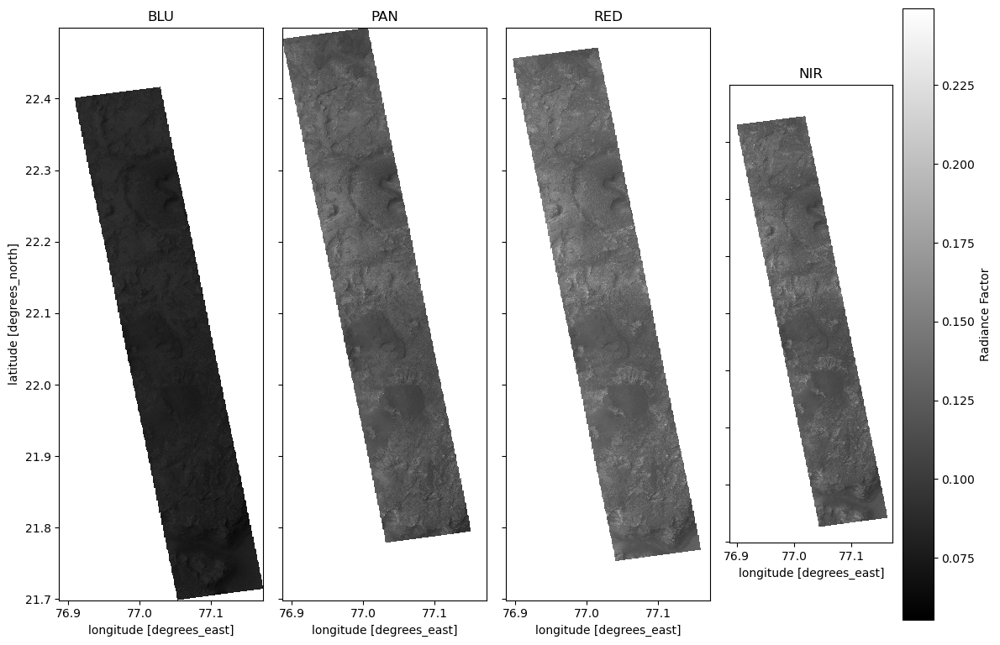

In [37]:
fig, ax = plt.subplots(figsize=(12, 8), sharey=True, ncols=4)

cassis_la.sel(band='BLU').plot(cmap='gray',ax=ax[0], vmin=vmin, vmax=vmax)
ax[0].set_aspect('equal', adjustable='box')
ax[0].set_title('BLU')
# only show the colorbar on the last plot
ax[0].collections[0].colorbar.remove()

cassis_la.sel(band='PAN').plot(cmap='gray',ax=ax[1], vmin=vmin, vmax=vmax)
ax[1].set_aspect('equal', adjustable='box')
ax[1].set_title('PAN')
ax[1].set_ylabel('') # only show y label on the first plot
ax[1].collections[0].colorbar.remove()

cassis_la.sel(band='RED').plot(cmap='gray',ax=ax[2], vmin=vmin, vmax=vmax)
ax[2].set_aspect('equal', adjustable='box')
ax[2].set_title('RED')
ax[2].set_ylabel('') # only show y label on the first plot
ax[2].collections[0].colorbar.remove()

cassis_la.sel(band='NIR').plot(cmap='gray',ax=ax[3], vmin=vmin, vmax=vmax)
ax[3].set_aspect('equal', adjustable='box')
ax[3].set_title('NIR')
ax[3].set_ylabel('') # only show y label on the first plot

# label colorbar as Radiance Factor
ax[3].collections[0].colorbar.set_label('Radiance Factor')

fig.tight_layout()

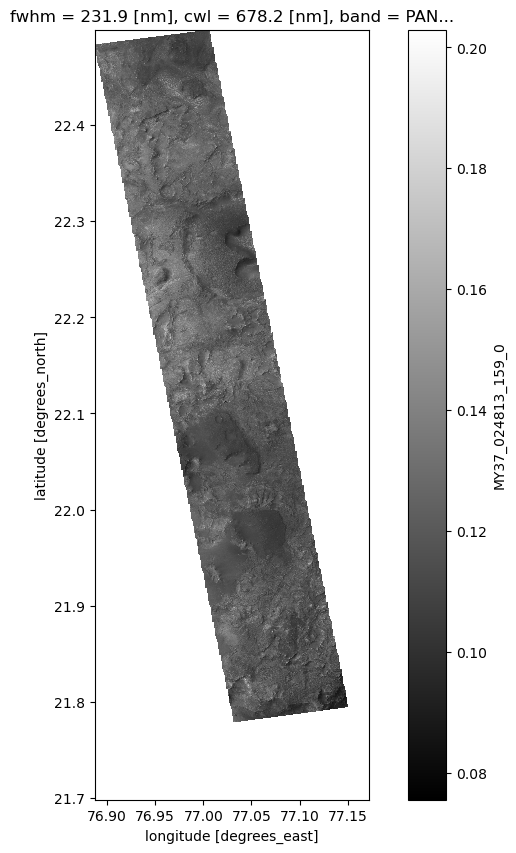

In [38]:
(cassis_cube.da.sel(band='PAN')/cos_mu).rio.reproject(cassis_cube.geo_crs).plot(cmap='gray',figsize=(10, 10))
# make sure that 1 degree in x is the same as 1 degree in y
plt.gca().set_aspect('equal', adjustable='box')

# CaSSIS x CaRDR Overplot

Let's downsample the CaSSIS cube to the CaRDR resolution

In [39]:
cassis_pan_dwnsmpl = cassis_cube.da.rio.reproject_match(cardr_tile.da)
cassis_pan_dwnsmpl = cassis_pan_dwnsmpl.where(cassis_pan_dwnsmpl.data != cassis_pan_dwnsmpl._FillValue, np.nan)

In [40]:
minx, miny, maxx, maxy = cassis_cube.da.rio.reproject(cassis_cube.geo_crs).rio.bounds()

In [41]:
minx, miny, maxx, maxy

(76.88736155871564, 21.69856093004329, 77.17232451752784, 22.499135540236804)

In [42]:
cassis_region = (minx*1, miny*0.995, maxx*1.005, maxy*1)

In [43]:
cassis_region

(76.88736155871564, 21.590068125393074, 77.55818614011547, 22.499135540236804)

In [44]:
tile_subset = cardr_tile.da.rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)

We have an offset problem, so we need to perform CaSSIS -> CaRDR pixel coregistration.

This is what planetary arosics is for after all.

In [49]:
def convert2geoarray(da):
    # check if da is in geo CRS
    if not da.rio.crs.is_geographic:
        geo_crs = da.rio.crs.from_wkt((CRS.from_wkt(da.rio.crs.to_wkt()).geodetic_crs.to_wkt()))
        da = da.rio.reproject(geo_crs)
    transform = da.rio.transform().to_gdal()
    projection = da.rio.crs.to_wkt()
    return ga.GeoArray(da.data, transform, projection)

def arosics_coreg(base_da, target_da):
    """Function for performing coregistration using AROSICS
    """    
    bands = base_da.band.values

    for band in ['PAN']:
        # get base and target and convert to GeoArrays, in geographic CRS
        base_ga = convert2geoarray(base_da.sel(band=band))
        target_ga = convert2geoarray(target_da.sel(band=band))

        crg = arosics.COREG(base_ga,target_ga, ws=(64,64), max_shift=20)
        crg.calculate_spatial_shifts()
        crg.correct_shifts()

    shifted = {}
    for band in bands:
        target_ga = convert2geoarray(target_da.sel(band=band))
        shifted[band] = arosics.DESHIFTER(target_ga, crg.coreg_info).correct_shifts()
        
    coreg_info = shifted['PAN']
    shifted_arr = np.stack([shifted[band]['arr_shifted'] for band in cassis_cube.da.band.values], axis=0)

    # Extract components
    arr = coreg_info['arr_shifted']          # 2D float32 array
    geotransform = coreg_info['updated geotransform']
    projection = coreg_info['updated projection']

    # Convert geotransform to Affine transform
    # GDAL geotransform: (x_origin, x_res, x_skew, y_origin, y_skew, y_res)
    transform = Affine.from_gdal(*geotransform)

    # Build coordinate arrays
    bands, rows, cols = shifted_arr.shape
    xs = np.array([transform.c + transform.a * (j + 0.5) for j in range(cols)])
    ys = np.array([transform.f + transform.e * (i + 0.5) for i in range(rows)])

    # Create DataArray
    da = xr.DataArray(
        shifted_arr,
        dims=["band", "y", "x"],
        coords={"band": cassis_cube.da.band.values, "y": ys, "x": xs}
    )

    # Attach spatial metadata
    da = da.rio.write_transform(transform)
    da = da.rio.write_crs(projection)
    da = da.rio.write_nodata(np.nan)
    
    return da

In [50]:
shifted_da = arosics_coreg(tile_subset, cassis_cube.da)

Calculating footprint polygon and actual data corner coordinates for reference image...
Bounding box of calculated footprint for reference image:
	(76.88640353464804, 21.589255976666806, 77.55928500323112, 22.500088503226564)
Automatically detected nodata value for GeoArray_CoReg 'IN_MEM': nan
Calculating footprint polygon and actual data corner coordinates for image to be shifted...


Polygonize progress     |==================================================| 100.0% Complete  => 0:00:00


Bounding box of calculated footprint for image to be shifted:
	(76.88736155871564, 21.778706762209218, 77.15029970868834, 22.499135540236804)
Matching window position (X,Y): 77.01891345629979/22.139191830184537
Detected integer shifts (X/Y):                            5/14
Detected subpixel shifts (X/Y):                           -0.2133989781141281/-0.16746757924556732
Calculated total shifts in fft pixel units (X/Y):         4.786601021885872/13.832532420754433
Calculated total shifts in reference pixel units (X/Y):   4.786601021885872/13.832532420754433
Calculated total shifts in target pixel units (X/Y):      110.96110793849111/320.6603424818698
Calculated map shifts (X,Y):                              0.00754289256470031/-0.021797786251756435
Calculated absolute shift vector length in map units:     0.023065964400385972
Calculated angle of shift vector in degrees from North:   340.9123645809416
Original map info: ['Geographic Lat/Lon', 1.0, 1.0, 76.8873615587156, 22.4991355402368,

Warping progress     |======--------------------------------------------| 12.0% Complete  => 0:00:00

Image similarity within the matching window (SSIM before/after correction): 0.0497 => nan
Estimated reliability of the calculated shifts:  45.8%
Correcting geometric shifts...


Warping progress     |==================================================| 100.0% Complete  => 0:00:00
Warping progress     |============--------------------------------------| 25.0% Complete  => 0:00:00

... (4 outputs left out)

Automatically detected nodata value for GeoArray 'IN_MEM': nan
Correcting geometric shifts...


Warping progress     |==================================================| 100.0% Complete  => 0:00:00
Warping progress     |============--------------------------------------| 25.0% Complete  => 0:00:00

Automatically detected nodata value for GeoArray 'IN_MEM': nan
Correcting geometric shifts...


Warping progress     |==================================================| 100.0% Complete  => 0:00:00


In [51]:
cos_mu

np.float64(0.9105899384450235)

In [52]:
import numpy as np
from shapely.geometry import shape
import rasterio.features
from shapely.ops import unary_union

def extract_footprint(da):
    # Mask valid (non-NaN) pixels
    valid_mask = np.where(np.isnan(da.values), 0, 1).astype('uint8')

    # Vectorize the valid area
    shapes = rasterio.features.shapes(valid_mask, transform=da.rio.transform())
    polygons = [shape(geom) for geom, val in shapes if val == 1]

    # Dissolve into one shape
    footprint = unary_union(polygons)

    x, y = footprint.exterior.xy

    return x,y 

def colour_extract_footprint(da):
    """Create a footprint as for the above, but only include valide pixels
    across the bands of the given da

    :param da: _description_
    :type da: _type_
    """    
    # Mask valid (non-NaN) pixels across all bands
    valid_mask = np.where(np.isnan(da.values).any(axis=0), 0, 1).astype('uint8')

    # Vectorize the valid area
    shapes = rasterio.features.shapes(valid_mask, transform=da.rio.transform())
    polygons = [shape(geom) for geom, val in shapes if val == 1]

    # Dissolve into one shape
    footprint = unary_union(polygons)
    x, y = footprint.exterior.xy
    return x,y

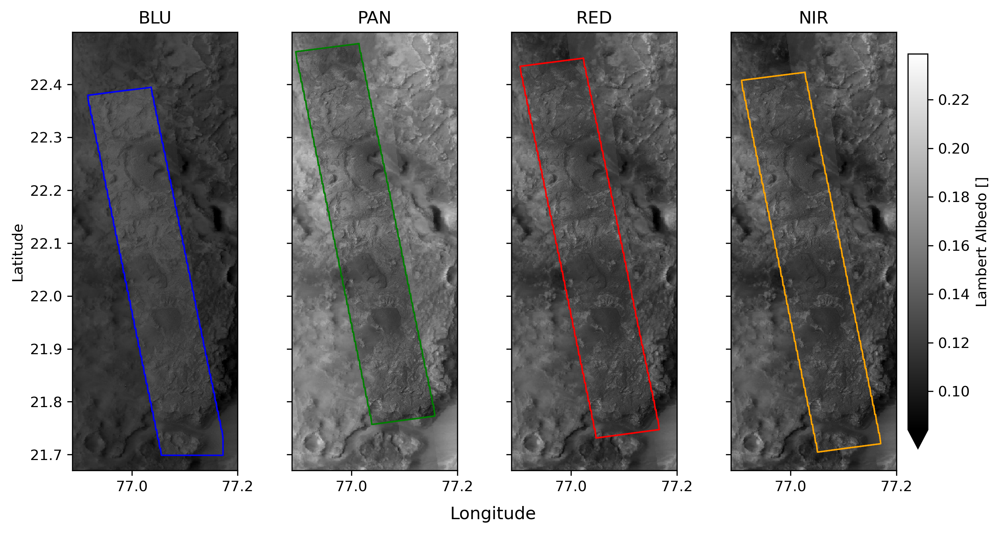

In [53]:
fig, ax = plt.subplots(figsize=(10, 5), sharex=True, sharey=True, ncols=4, dpi=300)

vmin, vmax = (shifted_da/cos_mu).sel(band='BLU').min(), (shifted_da/cos_mu).sel(band='BLU').max()
tile_subset.sel(band='BLU').plot(cmap='gray',ax=ax[0], vmin=vmin, vmax=vmax, rasterized=True)
(shifted_da/cos_mu).sel(band='BLU').plot(cmap='gray',ax=ax[0], vmin=vmin, vmax=vmax, rasterized=True)
ax[0].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='BLU'))
ax[0].plot(x, y, color='blue', linewidth=1)
ax[0].set_title('BLU')
ax[0].set_xlabel('') # drop x label
ax[0].set_ylabel('Latitude') # only show y label on the first plot
ax[0].collections[0].colorbar.remove()
ax[0].collections[1].colorbar.remove()

vmin, vmax = (shifted_da/cos_mu).sel(band='PAN').min(), (shifted_da/cos_mu).sel(band='PAN').max()
tile_subset.sel(band='PAN').plot(cmap='gray',ax=ax[1], vmin=vmin, vmax=vmax, rasterized=True)
(shifted_da/cos_mu).sel(band='PAN').plot(cmap='gray',ax=ax[1], vmin=vmin, vmax=vmax, rasterized=True)
ax[1].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='PAN'))
ax[1].plot(x, y, color='green', linewidth=1)
ax[1].set_title('PAN')
ax[1].set_xlabel('') # drop x label
ax[1].set_ylabel('') # only show y label on the first plot
ax[1].collections[0].colorbar.remove()
ax[1].collections[1].colorbar.remove()

vmin, vmax = (shifted_da/cos_mu).sel(band='RED').min(), (shifted_da/cos_mu).sel(band='RED').max()
tile_subset.sel(band='RED').plot(cmap='gray',ax=ax[2], vmin=vmin, vmax=vmax, rasterized=True)
(shifted_da/cos_mu).sel(band='RED').plot(cmap='gray',ax=ax[2], vmin=vmin, vmax=vmax, rasterized=True)
ax[2].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='RED'))
ax[2].plot(x, y, color='red', linewidth=1)
ax[2].set_title('RED')
ax[2].set_xlabel('') # drop x label
ax[2].set_ylabel('') # only show y label on the first plot
ax[2].collections[0].colorbar.remove()
ax[2].collections[1].colorbar.remove()

vmin, vmax = (shifted_da/cos_mu).sel(band='NIR').min(), (shifted_da/cos_mu).sel(band='NIR').max()
tile_subset.sel(band='NIR').plot(cmap='gray',ax=ax[3], vmin=vmin, vmax=vmax, rasterized=True, cbar_kwargs={'shrink': 0.9})
(shifted_da/cos_mu).sel(band='NIR').plot(cmap='gray',ax=ax[3], vmin=vmin, vmax=vmax, rasterized=True, cbar_kwargs={'shrink': 0.9})
ax[3].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='NIR'))
ax[3].plot(x, y, color='orange', linewidth=1)
ax[3].set_title('NIR')
ax[3].set_xlabel('') # drop x label
ax[3].set_ylabel('') # only show y label on the first plot
# ax[3].collections[0].colorbar.set_label('Lambert Albedo')
ax[3].collections[1].colorbar.remove()

ax[0].set_ylim(bottom=21.67)
ax[0].set_xlim(right=77.2)

fig.supxlabel('Longitude')

fig.tight_layout(w_pad=0.0)

# save the figure as a svg
out_file = out_dir / "cardr_cassis_la_comparison_grayscale.svg"
fig.savefig(out_file, format='svg', dpi=600)

In [54]:
# import hvplot.xarray

# tile_subset = cardr_tile.da.rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)

# base = tile_subset.sel(band='PAN').hvplot.image(cmap="gray", data_aspect=1, frame_width=500, frame_height=700)

# orig = (cassis_cube.da.sel(band='PAN')/cos_mu).rio.reproject(cassis_cube.geo_crs).hvplot.image(cmap="gray")

# overlay = (shifted_da.sel(band='PAN')/cos_mu).hvplot.image(cmap="gray")

# plot0 = base * orig
# plot1 = base * overlay
# plot2 = base

# plot0 + plot1 + plot2

In [55]:
# import hvplot.xarray

# tile_subset = cardr_tile.da.rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)

# base = tile_subset.sel(band='NIR').hvplot.image(cmap="gray", data_aspect=1, frame_width=500, frame_height=700)

# orig = (cassis_cube.da.sel(band='NIR')/cos_mu).rio.reproject(cassis_cube.geo_crs).hvplot.image(cmap="gray")

# overlay = (shifted_da.sel(band='NIR')/cos_mu).hvplot.image(cmap="gray")

# plot0 = base * orig
# plot1 = base * overlay
# plot2 = base

# plot0 + plot1 + plot2

# Downsampling the CaSSIS Cube to CaRDR

There are a few options for converting the CaSSIS cube to matching pixel resolution of the CaRDR tile.

In [56]:
minx, miny, maxx, maxy = cassis_cube.da.rio.reproject(cassis_cube.geo_crs).rio.bounds()
miny = 21.67
maxx = 77.2
cassis_region = (minx, miny, maxx, maxy)
tile_subset = cardr_tile.da.rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)

In [57]:
cassis_region

(76.88736155871564, 21.67, 77.2, 22.499135540236804)

In [58]:
cassis_region

(76.88736155871564, 21.67, 77.2, 22.499135540236804)

We can use rioxarray reproject_match

In [59]:
from rasterio.enums import Resampling

cassis_dwnsmpl = shifted_da.rio.reproject_match(tile_subset, resampling=Resampling.bilinear)
# update the coordinates to avoid floating point error
# cassis_dwnsmpl = cassis_dwnsmpl.assign_coords(x=tile_subset.x, y=tile_subset.y)

cassis_dwnsmpl = cassis_dwnsmpl.where(cassis_dwnsmpl.data != cassis_dwnsmpl._FillValue, np.nan)

In [60]:
cassis_dwnsmpl_geo = cassis_dwnsmpl.rio.reproject(cassis_cube.geo_crs)

In [61]:
# explicitly set the x and y coordinates to be the same as the tile subset to avoid floating point issues
cassis_dwnsmpl_geo = cassis_dwnsmpl_geo.assign_coords(x=tile_subset.x, y=tile_subset.y)

In [62]:
perr_if = 100 * (tile_subset - cassis_dwnsmpl_geo) / cassis_dwnsmpl_geo
perr_la = 100 * (tile_subset - (cassis_dwnsmpl_geo/cos_mu)) / (cassis_dwnsmpl_geo/cos_mu)

Something strange is happening when we try and subtract the downsampled cube from the tile subset

In [63]:
np.nanpercentile(perr_if, [1, 99])

array([-5.45457723, 27.02583214])

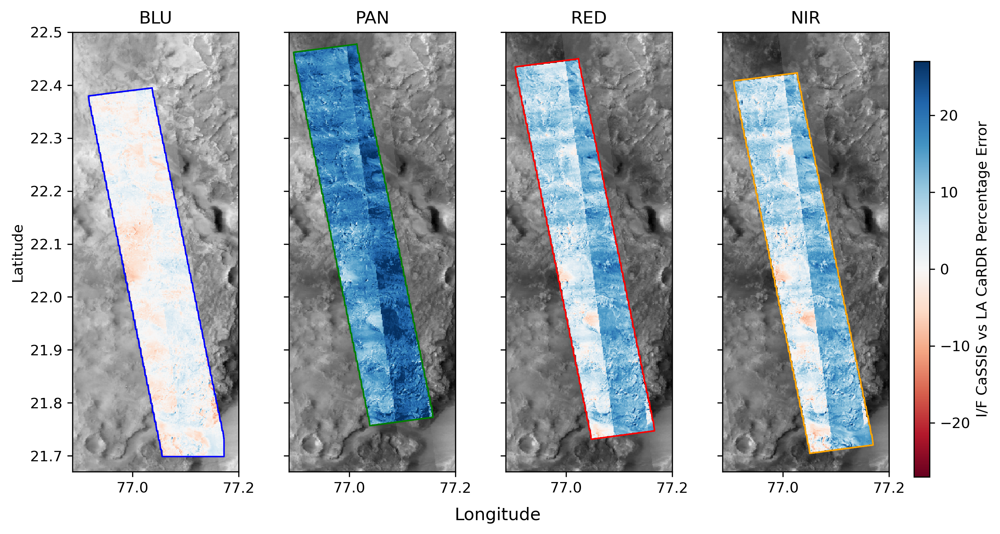

In [64]:
# I/F Percentage Error

fig, ax = plt.subplots(figsize=(10, 5), sharex=True, sharey=True, ncols=4, dpi=300)

# vmin, vmax = perr_if.min(), perr_if.max()
# get the 1% percentiles for vmin and vmax
vmin, vmax = np.nanpercentile(perr_if, [1, 99])
vlim = max(abs(vmin), abs(vmax))
vmin, vmax = -vlim, vlim

tile_subset.sel(band='BLU').plot(cmap='gray',ax=ax[0], rasterized=True)
perr_if.sel(band='BLU').plot(cmap='RdBu',ax=ax[0], vmin=vmin, vmax=vmax, rasterized=True)
ax[0].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='BLU'))
ax[0].plot(x, y, color='blue', linewidth=1)
ax[0].set_title('BLU')
ax[0].set_xlabel('') # drop x label
ax[0].set_ylabel('Latitude') # only show y label on the first plot
ax[0].collections[0].colorbar.remove()
ax[0].collections[1].colorbar.remove()

tile_subset.sel(band='PAN').plot(cmap='gray',ax=ax[1], rasterized=True)
perr_if.sel(band='PAN').plot(cmap='RdBu',ax=ax[1], vmin=vmin, vmax=vmax, rasterized=True)
ax[1].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='PAN'))
ax[1].plot(x, y, color='green', linewidth=1)
ax[1].set_title('PAN')
ax[1].set_xlabel('') # drop x label
ax[1].set_ylabel('') # only show y label on the first plot
ax[1].collections[0].colorbar.remove()
ax[1].collections[1].colorbar.remove()

tile_subset.sel(band='RED').plot(cmap='gray',ax=ax[2], rasterized=True)
perr_if.sel(band='RED').plot(cmap='RdBu',ax=ax[2], vmin=vmin, vmax=vmax, rasterized=True)
ax[2].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='RED'))
ax[2].plot(x, y, color='red', linewidth=1)
ax[2].set_title('RED')
ax[2].set_xlabel('') # drop x label
ax[2].set_ylabel('') # only show y label on the first plot
ax[2].collections[0].colorbar.remove()
ax[2].collections[1].colorbar.remove()

tile_subset.sel(band='NIR').plot(cmap='gray',ax=ax[3], rasterized=True, cbar_kwargs={'shrink': 0.9})
perr_if.sel(band='NIR').plot(cmap='RdBu',ax=ax[3], vmin=vmin, vmax=vmax, rasterized=True, cbar_kwargs={'shrink': 0.9})
ax[3].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='NIR'))
ax[3].plot(x, y, color='orange', linewidth=1)
ax[3].set_title('NIR')
ax[3].set_xlabel('') # drop x label
ax[3].set_ylabel('') # only show y label on the first plot
ax[3].collections[0].colorbar.remove()
ax[3].collections[1].colorbar.remove()

im = ax[0].collections[1]

ax[0].set_ylim(bottom=21.67)
ax[0].set_xlim(right=77.2)

fig.supxlabel('Longitude')
fig.tight_layout(w_pad=0.0)

fig.subplots_adjust(right=0.92)

# add colorbar in a manually-placed axes to the right of all subplots
cax = fig.add_axes([0.90, 0.1, 0.015, 0.8])
cbar = fig.colorbar(im, cax=cax, orientation='vertical')
cbar.set_label('I/F CaSSIS vs LA CaRDR Percentage Error')

# save the figure as a svg
out_file = out_dir / "cardr_cassis_if_comparison_pcterr.svg"
fig.savefig(out_file, format='svg', dpi=600)

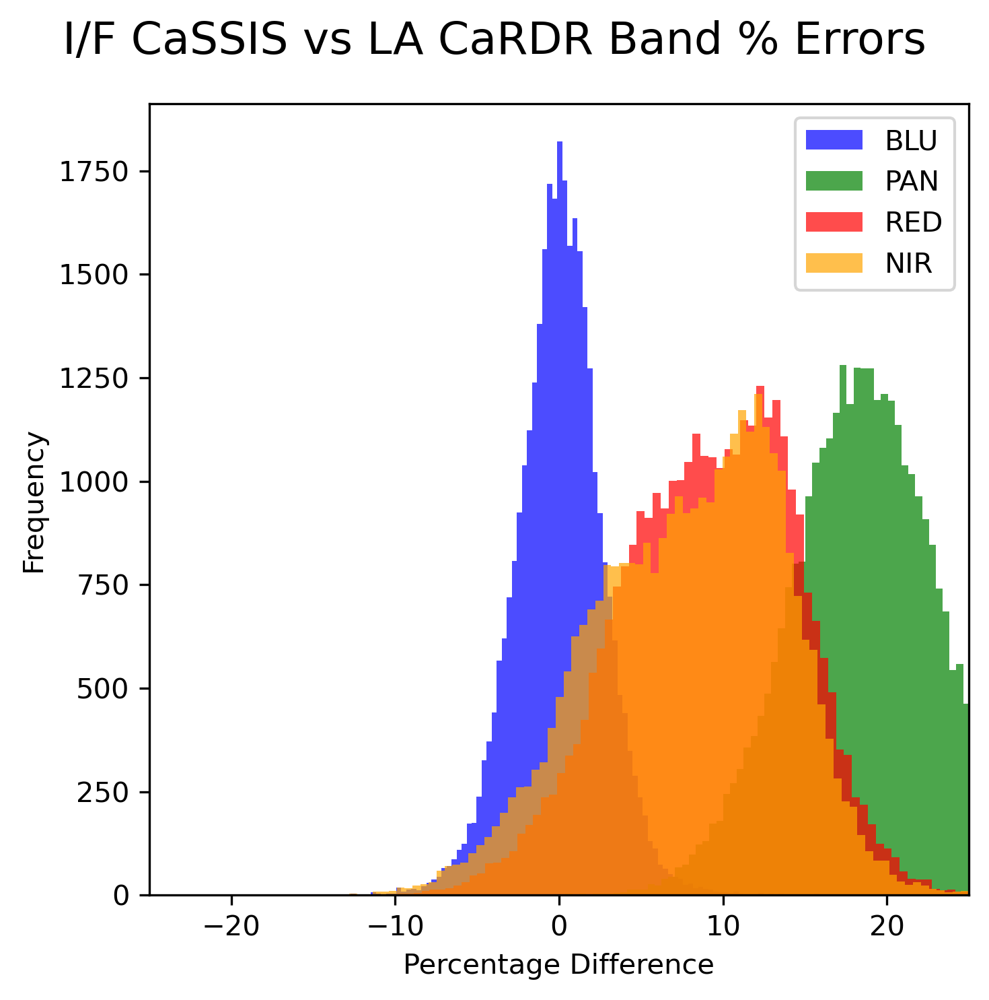

In [65]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

ax.hist(perr_if.sel(band='BLU').data[~np.isnan(perr_if.sel(band='BLU').data)].flatten(), bins=128, color='blue', alpha=0.7, label='BLU')
ax.hist(perr_if.sel(band='PAN').data[~np.isnan(perr_if.sel(band='PAN').data)].flatten(), bins=128, color='green', alpha=0.7, label='PAN')
ax.hist(perr_if.sel(band='RED').data[~np.isnan(perr_if.sel(band='RED').data)].flatten(), bins=128, color='red', alpha=0.7, label='RED')
ax.hist(perr_if.sel(band='NIR').data[~np.isnan(perr_if.sel(band='NIR').data)].flatten(), bins=128, color='orange', alpha=0.7, label='NIR')
# clip xmin and xmax = ±20
ax.set_xlim(-25, 25)
# y is frequency
ax.set_xlabel('Percentage Difference')
ax.set_ylabel('Frequency')
fig.suptitle('I/F CaSSIS vs LA CaRDR Band % Errors', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()

# save the figure as a svg
out_file = out_dir / "cardr_cassis_if_pcterr_hist.svg"
fig.savefig(out_file, format='svg', dpi=600)

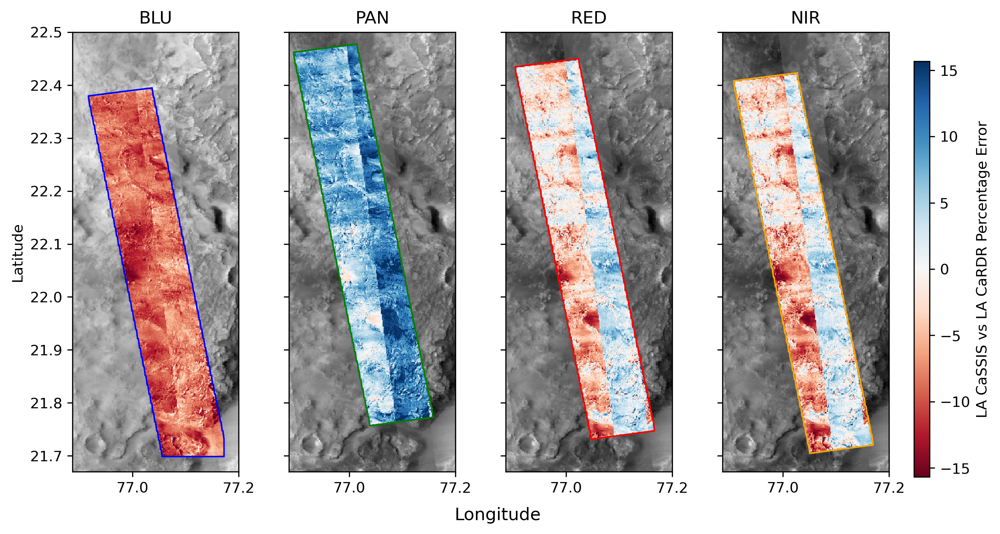

In [66]:
# LA Percentage Error

fig, ax = plt.subplots(figsize=(10, 5), sharex=True, sharey=True, ncols=4, dpi=300)

vmin, vmax = perr_la.min(), perr_la.max()

# get the 1% percentiles for vmin and vmax
vmin, vmax = np.nanpercentile(perr_la, [1, 99])
vlim = max(abs(vmin), abs(vmax))
vmin, vmax = -vlim, vlim

tile_subset.sel(band='BLU').plot(cmap='gray',ax=ax[0], rasterized=True)
perr_la.sel(band='BLU').plot(cmap='RdBu',ax=ax[0], vmin=vmin, vmax=vmax, rasterized=True)
ax[0].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='BLU'))
ax[0].plot(x, y, color='blue', linewidth=1)
ax[0].set_title('BLU')
ax[0].set_xlabel('') # drop x label
ax[0].set_ylabel('Latitude') # only show y label on the first plot
ax[0].collections[0].colorbar.remove()
ax[0].collections[1].colorbar.remove()

tile_subset.sel(band='PAN').plot(cmap='gray',ax=ax[1], rasterized=True)
perr_la.sel(band='PAN').plot(cmap='RdBu',ax=ax[1], vmin=vmin, vmax=vmax, rasterized=True)
ax[1].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='PAN'))
ax[1].plot(x, y, color='green', linewidth=1)
ax[1].set_title('PAN')
ax[1].set_xlabel('') # drop x label
ax[1].set_ylabel('') # only show y label on the first plot
ax[1].collections[0].colorbar.remove()
ax[1].collections[1].colorbar.remove()

tile_subset.sel(band='RED').plot(cmap='gray',ax=ax[2], rasterized=True)
perr_la.sel(band='RED').plot(cmap='RdBu',ax=ax[2], vmin=vmin, vmax=vmax, rasterized=True)
ax[2].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='RED'))
ax[2].plot(x, y, color='red', linewidth=1)
ax[2].set_title('RED')
ax[2].set_xlabel('') # drop x label
ax[2].set_ylabel('') # only show y label on the first plot
ax[2].collections[0].colorbar.remove()
ax[2].collections[1].colorbar.remove()

tile_subset.sel(band='NIR').plot(cmap='gray',ax=ax[3], rasterized=True, cbar_kwargs={'shrink': 0.9})
perr_la.sel(band='NIR').plot(cmap='RdBu',ax=ax[3], vmin=vmin, vmax=vmax, rasterized=True, cbar_kwargs={'shrink': 0.9})
ax[3].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='NIR'))
ax[3].plot(x, y, color='orange', linewidth=1)
ax[3].set_title('NIR')
ax[3].set_xlabel('') # drop x label
ax[3].set_ylabel('') # only show y label on the first plot
ax[3].collections[0].colorbar.remove()
ax[3].collections[1].colorbar.remove()

ax[0].set_ylim(bottom=21.67)
ax[0].set_xlim(right=77.2)

fig.supxlabel('Longitude')

fig.tight_layout(w_pad=0.0)

fig.subplots_adjust(right=0.92)

im = ax[0].collections[1]

# add colorbar in a manually-placed axes to the right of all subplots
cax = fig.add_axes([0.90, 0.1, 0.015, 0.8])
cbar = fig.colorbar(im, cax=cax, orientation='vertical')
cbar.set_label('LA CaSSIS vs LA CaRDR Percentage Error')

# save the figure as a svg
out_file = out_dir / "cardr_cassis_la_comparison_pcterr.svg"
fig.savefig(out_file, format='svg', dpi=600)

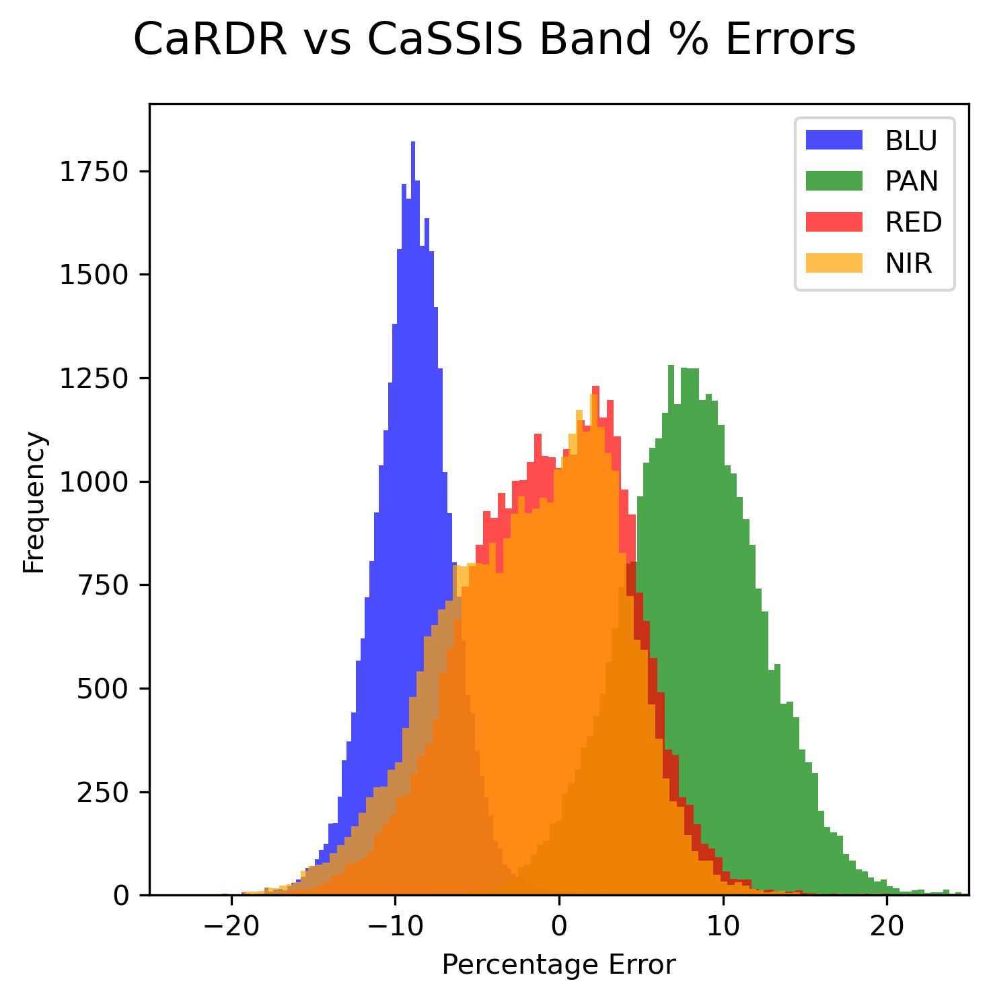

In [67]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

ax.hist(perr_la.sel(band='BLU').data[~np.isnan(perr_la.sel(band='BLU').data)].flatten(), bins=128, color='blue', alpha=0.7, label='BLU')
ax.hist(perr_la.sel(band='PAN').data[~np.isnan(perr_la.sel(band='PAN').data)].flatten(), bins=128, color='green', alpha=0.7, label='PAN')
ax.hist(perr_la.sel(band='RED').data[~np.isnan(perr_la.sel(band='RED').data)].flatten(), bins=128, color='red', alpha=0.7, label='RED')
ax.hist(perr_la.sel(band='NIR').data[~np.isnan(perr_la.sel(band='NIR').data)].flatten(), bins=128, color='orange', alpha=0.7, label='NIR')
# clip xmin and xmax = ±20
ax.set_xlim(-25, 25)
# y is frequency
ax.set_xlabel('Percentage Error')
ax.set_ylabel('Frequency')
fig.suptitle('CaRDR vs CaSSIS Band % Errors', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()

# save the figure as a svg
out_file = out_dir / "cardr_cassis_la_comparison_pcterr_hist.svg"
fig.savefig(out_file, format='svg', dpi=600)

Now let's look at statistics after performing band stretches

In [68]:
# make a stretch cube
tile_subset

<xarray.DataArray (band: 4, y: 527, x: 200)> Size: 2MB
array([[[0.07839729, 0.07941079, 0.07870682, ..., 0.08114074,
         0.08166597, 0.07910002],
        [0.07947021, 0.07947759, 0.07799535, ..., 0.08183317,
         0.08257442, 0.08079135],
        [0.07936557, 0.07947759, 0.07799535, ..., 0.08183317,
         0.08257442, 0.08324952],
        ...,
        [0.07509815, 0.07505293, 0.07456952, ..., 0.08485051,
         0.08520747, 0.08538025],
        [0.07577101, 0.07575469, 0.07542769, ..., 0.08477543,
         0.08422912, 0.08413381],
        [0.07869092, 0.07802777, 0.07831667, ..., 0.08414256,
         0.08422912, 0.0830726 ]],

       [[0.12923026, 0.13125782, 0.13052061, ..., 0.15034023,
         0.15286714, 0.14876826],
        [0.1305669 , 0.13158742, 0.12788403, ..., 0.15170088,
         0.15330358, 0.15581033],
        [0.13002662, 0.13158742, 0.12788403, ..., 0.15170088,
         0.15330358, 0.16184394],
...
        [0.1499406 , 0.14989544, 0.1477455 , ..., 0.15928566,
         0.15931869, 0.15958798],
        [0.1506983 , 0.15084656, 0.1499566 , ..., 0.15799667,
         0.15646216, 0.15653805],
        [0.15373455, 0.15543352, 0.15482946, ..., 0.15704153,
         0.15646216, 0.1548252 ]],

       [[0.11448056, 0.11918929, 0.11903863, ..., 0.1440438 ,
         0.14780939, 0.14585045],
        [0.11618605, 0.11936969, 0.11534978, ..., 0.14437185,
         0.1482741 , 0.15687697],
        [0.11505495, 0.11936969, 0.11534978, ..., 0.14437185,
         0.1482741 , 0.16468851],
        ...,
        [0.14072563, 0.14023173, 0.13753283, ..., 0.14754692,
         0.14708817, 0.1472477 ],
        [0.14131933, 0.14154166, 0.1398053 , ..., 0.14629926,
         0.14503965, 0.14486556],
        [0.14377283, 0.14541532, 0.14457572, ..., 0.14513157,
         0.14503965, 0.1432916 ]]], shape=(4, 527, 200), dtype=float32)
Coordinates:
  * band         (band) <U3 48B 'BLU' 'PAN' 'RED' 'NIR'
    cwl          (band) float64 32B 500.0 675.0 836.0 937.0
  * y            (y) float64 4kB 22.5 22.5 22.5 22.49 ... 21.67 21.67 21.67
  * x            (x) float64 2kB 76.89 76.89 76.89 76.89 ... 77.2 77.2 77.2 77.2
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    WAVELENGTH:     500.0nm
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      Lambert Albedo
    units:          
    _FillValue:     65535.0

In [69]:
cassis_dwnsmpl_geo

<xarray.DataArray (band: 4, y: 527, x: 200)> Size: 2MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(4, 527, 200), dtype=float32)
Coordinates:
  * band         (band) <U3 48B 'NIR' 'RED' 'PAN' 'BLU'
  * y            (y) float64 4kB 22.5 22.5 22.5 22.49 ... 21.67 21.67 21.67
  * x            (x) float64 2kB 76.89 76.89 76.89 76.89 ... 77.2 77.2 77.2 77.2
    spatial_ref  int64 8B 0
Attributes:
    _FillValue:  nan

## Making a wider tile subset for colour plot

In [70]:
minx, miny, maxx, maxy = cassis_cube.da.rio.reproject(cassis_cube.geo_crs).rio.bounds()
miny = 21.67
maxx = 77.2
cassis_region = (minx, miny, maxx, maxy)
print(cassis_region)

(76.88736155871564, 21.67, 77.2, 22.499135540236804)


In [71]:
tile_subset = cardr_tile.da.rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)

In [72]:
from rasterio.enums import Resampling

cassis_dwnsmpl = shifted_da.rio.reproject_match(tile_subset, resampling=Resampling.bilinear)
# update the coordinates to avoid floating point error
# cassis_dwnsmpl = cassis_dwnsmpl.assign_coords(x=tile_subset.x, y=tile_subset.y)

cassis_dwnsmpl = cassis_dwnsmpl.where(cassis_dwnsmpl.data != cassis_dwnsmpl._FillValue, np.nan)

In [73]:
cassis_dwnsmpl_geo = cassis_dwnsmpl.rio.reproject(cassis_cube.geo_crs)

In [74]:
# explicitly set the x and y coordinates to be the same as the tile subset to avoid floating point issues
cassis_dwnsmpl_geo = cassis_dwnsmpl_geo.assign_coords(x=tile_subset.x, y=tile_subset.y)

In [75]:
cassis_dwn = (cassis_dwnsmpl_geo/cos_mu).sel(band=['NIR', 'RED', 'PAN', 'BLU'])
cassis_dwn_str = clip_and_normalise(cassis_dwn, percent=1.0)
# round to 3 decimal places
# cassis_dwn_str = cassis_dwn_str.round(3)

In [76]:
# for each band in cassis_dwnsmpl_geo, use the band as a mask for the corresponding band in the tile_subset,
# and make a new masked tile subset
masked_tile_subset = tile_subset.copy()
for band in cassis_dwnsmpl_geo.band.values:
    mask = ~np.isnan(cassis_dwnsmpl_geo.sel(band=band).data)
    masked_tile_subset.loc[dict(band=band)] = masked_tile_subset.sel(band=band).where(mask)
cardr_msk_str = clip_and_normalise(masked_tile_subset, percent=1.0)
cardr_nomsk_str = clip_and_normalise(tile_subset, percent=1.0)
# round to 3 decimal places
# cardr_msk_str = cardr_msk_str.round(3)
# cardr_nomsk_str = cardr_nomsk_str.round(3)

/var/folders/w4/44k32f413dd82lxmtw9456w80000gp/T/ipykernel_11533/201150846.py:14: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  return xr.concat(bands, dim="band")
/var/folders/w4/44k32f413dd82lxmtw9456w80000gp/T/ipykernel_11533/201150846.py:14: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  return xr.concat(bands

display the two figures in colour

In [77]:
# we need to get the min and max lims for the CaSSIS downsampled scene, 
# and then apply that to the tile_subset, and show the whole subset,
# and then apply it to the cassis original image, and show that
blu_lims = np.nanpercentile(masked_tile_subset.sel(band='BLU'), [1, 99])
pan_lims = np.nanpercentile(masked_tile_subset.sel(band='PAN'), [1, 99])
red_lims = np.nanpercentile(masked_tile_subset.sel(band='RED'), [1, 99])
nir_lims = np.nanpercentile(masked_tile_subset.sel(band='NIR'), [1, 99])

print(f"BLU lims: {blu_lims}")
print(f"PAN lims: {pan_lims}")
print(f"RED lims: {red_lims}") 
print(f"NIR lims: {nir_lims}")

BLU lims: [0.0614245  0.08330255]
PAN lims: [0.10835467 0.15381726]
RED lims: [0.10653666 0.15587026]
NIR lims: [0.09723998 0.14685667]


In [78]:
# now we need to apply these limits to produce a cassis_hrs_npb, a cassis_dwn_npb, a cardr_msk_npb, and a cardr_nomsk_npb
def apply_lims(da, lims):
    da_clipped = da.clip(min=lims[0], max=lims[1])
    da_normed = (da_clipped - lims[0]) / (lims[1] - lims[0])
    return da_normed

cassis_hrs_npb = (shifted_da/cos_mu).copy().sel(band=['NIR', 'PAN', 'BLU'])
cassis_dwn_str_npb = cassis_dwn.copy().sel(band=['NIR', 'PAN', 'BLU'])
cardr_msk_str_npb = masked_tile_subset.copy().sel(band=['NIR', 'PAN', 'BLU'])
cardr_nomsk_str_npb = tile_subset.copy().sel(band=['NIR', 'PAN', 'BLU'])

for band in ['NIR', 'PAN', 'BLU']:
    if band == 'BLU':
        lims = blu_lims
    elif band == 'PAN':
        lims = pan_lims
    elif band == 'RED':
        lims = red_lims
    elif band == 'NIR':
        lims = nir_lims
    else:
        raise ValueError(f"Unexpected band: {band}")
    
    cardr_msk_str_npb.loc[dict(band=band)] = apply_lims(cardr_msk_str_npb.sel(band=band), lims)
    cardr_nomsk_str_npb.loc[dict(band=band)] = apply_lims(cardr_nomsk_str_npb.sel(band=band), lims)

cassis_hrs_npb = clip_and_normalise(cassis_hrs_npb, percent=1.0)
cassis_dwn_str_npb = clip_and_normalise(cassis_dwn_str_npb, percent=1.0)

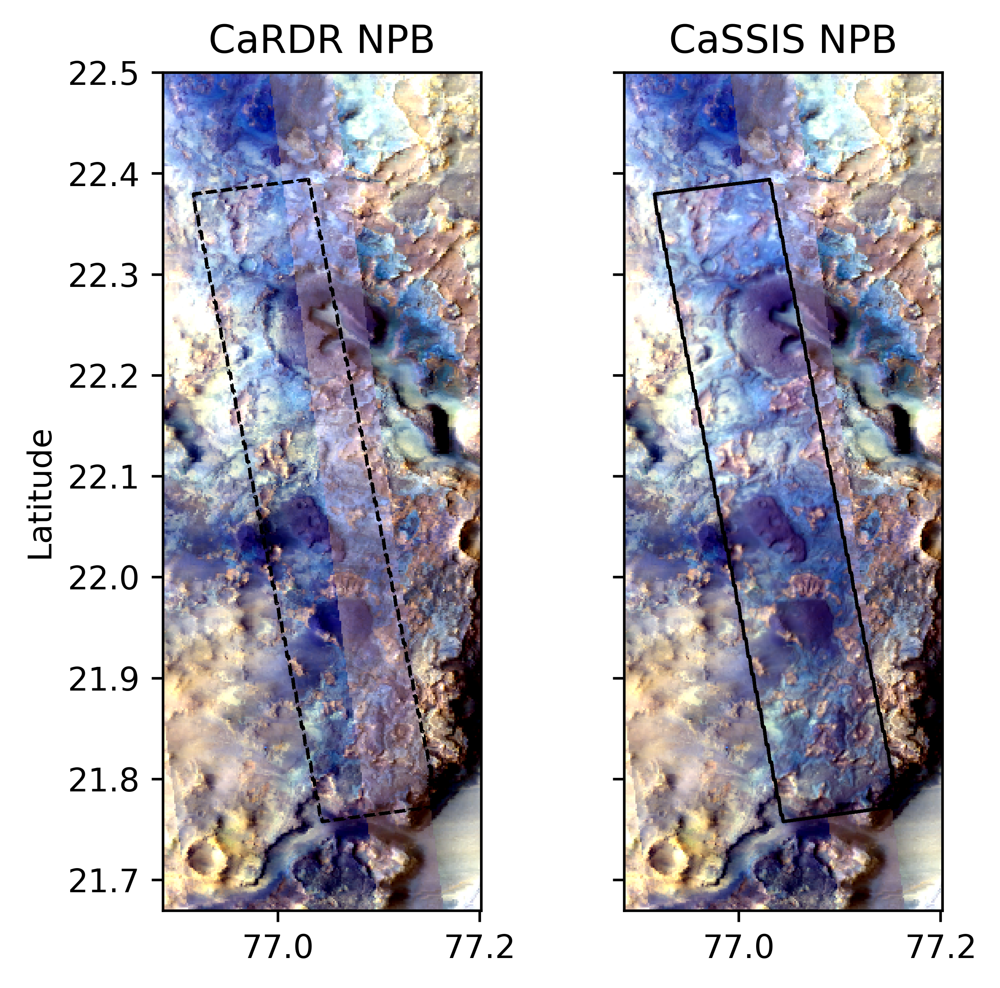

In [79]:
fig, ax = plt.subplots(figsize=(4.87, 4.33), sharex=True, sharey=True, ncols=2, dpi=600)

cardr_nomsk_str_npb.sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(ax=ax[0], vmin=0, vmax=1)
ax[0].set_aspect('equal', adjustable='box')
x,y = colour_extract_footprint(cassis_hrs_npb.sel(band=['NIR', 'PAN', 'BLU']))
ax[0].plot(x, y, color='black', ls='--', linewidth=1)
ax[0].set_title('CaRDR NPB')
ax[0].set_xlabel('') # drop x label
ax[0].set_ylabel('Latitude') # only show y label on the first plot

cardr_nomsk_str_npb.sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(ax=ax[1], vmin=0, vmax=1)
cassis_dwn_str_npb.sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(ax=ax[1], vmin=0, vmax=1)
# cassis_hrs_npb.sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(ax=ax[1], vmin=0, vmax=1)
ax[1].set_aspect('equal', adjustable='box')
x,y = colour_extract_footprint(cassis_hrs_npb.sel(band=['NIR', 'PAN', 'BLU']))
ax[1].plot(x, y, color='black', linewidth=1)
ax[1].set_title('CaSSIS NPB')
ax[1].set_xlabel('') # drop x label
ax[1].set_ylabel('') # only show y label on the first plot

# cardr_nomsk_str_npb.sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(ax=ax[2], vmin=0, vmax=1)
# cassis_dwn_str_npb.sel(band=['NIR', 'PAN', 'BLU']).plot.imshow(ax=ax[2], vmin=0, vmax=1)
# ax[2].set_aspect('equal', adjustable='box')
# x,y = colour_extract_footprint(cassis_hrs_npb.sel(band=['NIR', 'PAN', 'BLU']))
# ax[2].plot(x, y, color='black', linewidth=1)
# ax[2].set_title('CaSSIS NPB 90 m/pix')
# ax[2].set_xlabel('') # drop x label
# ax[2].set_ylabel('') # only show y label on the first plot

fig.tight_layout(w_pad=0.0)

# save the figure as a svg
out_file = out_dir / "cardr_cassis_npbs_comparison.svg"
fig.savefig(out_file, format='svg', dpi=600)

Whilst we're here, let's also show the metadata subset tiles

Text(0, 0.5, '')

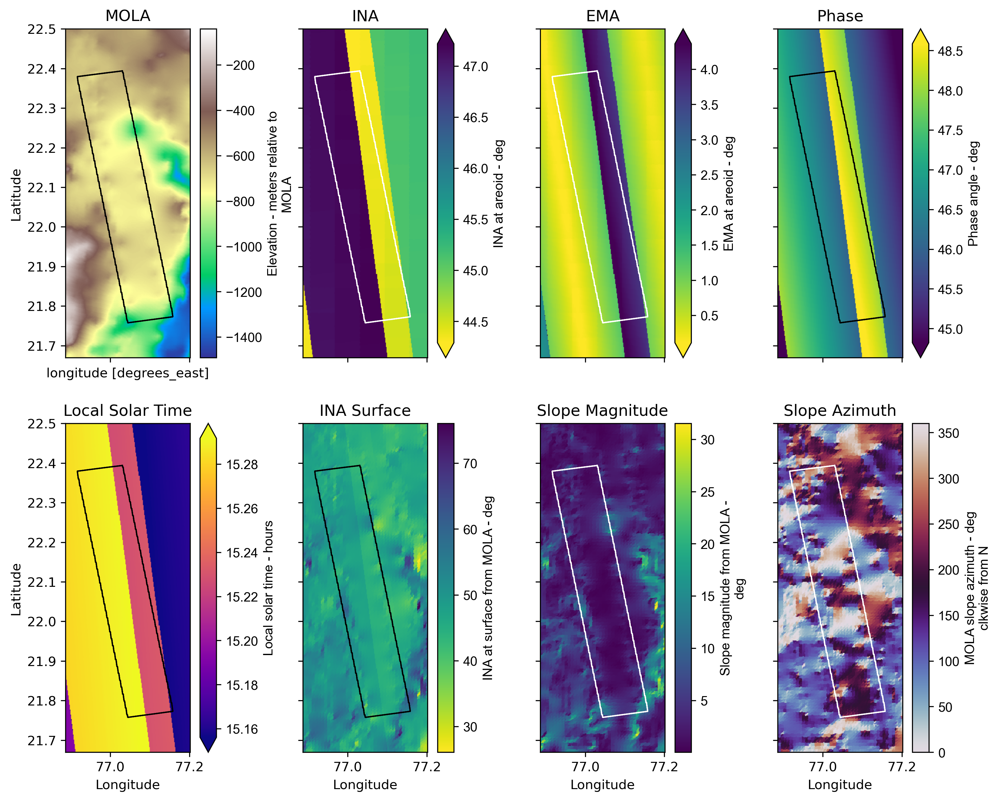

In [81]:
mola_subset = ddr.ds['Elevation - meters relative to MOLA'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
ina_subset = ddr.ds['INA at areoid - deg'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
ema_subset = ddr.ds['EMA at areoid - deg'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
phase_subset = ddr.ds['Phase angle - deg'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
ina_surface_subset = ddr.ds['INA at surface from MOLA - deg'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
azi_surface_subset = ddr.ds['MOLA slope azimuth - deg clkwise from N'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
slp_surface_subset = ddr.ds['Slope magnitude from MOLA - deg'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)
lst_subset = ddr.ds['Local solar time - hours'].rio.reproject(cassis_cube.geo_crs).rio.clip_box(*cassis_region)

fig, ax = plt.subplots(figsize=(12.5, 10), sharex=True, sharey=True, ncols=4, nrows=2, dpi=300)

# change font to arial
plt.rcParams['font.family'] = 'Arial'

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[0][0], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
mola_subset.plot.imshow(cmap='terrain', ax=ax[0][0], interpolation='bilinear')
ax[0][0].plot(x, y, color='black', linewidth=1) # plot the footprint from colour
ax[0][0].set_aspect('equal', adjustable='box')
ax[0][0].set_title('MOLA')
ax[0][1].set_xlabel('') # drop x label
ax[0][0].set_ylabel('Latitude') # only show y label on the first plot

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[0][1], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
ina_subset.plot.imshow(cmap='viridis_r', ax=ax[0][1], interpolation='bilinear', robust=True)#, vmin=0, vmax=90)
ax[0][1].plot(x, y, color='white', linewidth=1) # plot the footprint from colour
ax[0][1].set_aspect('equal', adjustable='box')
ax[0][1].set_title('INA')
ax[0][1].set_xlabel('') # drop x label
ax[0][1].set_ylabel('') # only show y label on the first plot

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[0][2], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
ema_subset.plot.imshow(cmap='viridis_r', ax=ax[0][2], interpolation='bilinear', robust=True)#, vmin=0, vmax=90)
ax[0][2].plot(x, y, color='white', linewidth=1) # plot the footprint from colour
ax[0][2].set_aspect('equal', adjustable='box')
ax[0][2].set_title('EMA')
ax[0][2].set_xlabel('') # drop x label
ax[0][2].set_ylabel('') # only show y label on the first plot

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[0][3], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
phase_subset.plot.imshow(cmap='viridis', ax=ax[0][3], interpolation='bilinear', robust=True)#, vmin=0, vmax=180)
ax[0][3].plot(x, y, color='black', linewidth=1) # plot the footprint from colour
ax[0][3].set_aspect('equal', adjustable='box')
ax[0][3].set_title('Phase')
ax[0][3].set_xlabel('') # drop x label
ax[0][3].set_ylabel('') # only show y label on the first plot

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[1][0], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
lst_subset.plot.imshow(cmap='plasma', ax=ax[1][0], interpolation='bilinear', robust=True)#, vmin=0, vmax=24)
ax[1][0].plot(x, y, color='black', linewidth=1) # plot the footprint from colour
ax[1][0].set_aspect('equal', adjustable='box')
ax[1][0].set_title('Local Solar Time')
ax[1][0].set_xlabel('Longitude') # only show x label on the first plot
ax[1][0].set_ylabel('Latitude') # only show y label on the first

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[1][1], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
ina_surface_subset.plot.imshow(cmap='viridis_r', ax=ax[1][1], interpolation='bilinear')#, vmin=0, vmax=90)
ax[1][1].plot(x, y, color='black', linewidth=1) # plot the footprint from colour
ax[1][1].set_aspect('equal', adjustable='box')
ax[1][1].set_title('INA Surface')
ax[1][1].set_xlabel('Longitude') # only show x label on the first plot
ax[1][1].set_ylabel('') # only show y label on the first plot   

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[1][2], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
slp_surface_subset.plot.imshow(cmap='viridis', ax=ax[1][2], interpolation='bilinear')
ax[1][2].plot(x, y, color='white', linewidth=1) # plot the footprint from colour
ax[1][2].set_aspect('equal', adjustable='box')
ax[1][2].set_title('Slope Magnitude')
ax[1][2].set_xlabel('Longitude') # only show x label on the first plot
ax[1][2].set_ylabel('') # only show y label on the first plot

# cardr_nomsk_str_npb.sel(band='PAN').plot.imshow(ax=ax[1][3], cmap='gray', vmin=0, vmax=1, add_colorbar=False)
azi_surface_subset.plot.imshow(cmap='twilight', ax=ax[1][3], interpolation='bilinear')#, vmin=0, vmax=360)
ax[1][3].plot(x, y, color='white', linewidth=1) # plot the footprint from colour
ax[1][3].set_aspect('equal', adjustable='box')
ax[1][3].set_title('Slope Azimuth')
ax[1][3].set_xlabel('Longitude') # only show x label on the first plot
ax[1][3].set_ylabel('') # only show y label on the first plot


# fig.tight_layout(w_pad=0.0)

# # save the figure as a svg
# out_file = out_dir / "cardr_cassis_npbs_context.svg"
# fig.savefig(out_file, format='svg', dpi=150)

In [82]:
out_file = out_dir / "cardr_cassis_npbs_context_dpi300.png"
fig.savefig(out_file, format='png', dpi=300)

In [83]:
# get ranges within footprint/mask
mola_subset.where(mask).min(), mola_subset.where(mask).max()
print(f"MOLA range within footprint: {mola_subset.where(mask).min().values} to {mola_subset.where(mask).max().values} m")
ina_subset.where(mask).min(), ina_subset.where(mask).max()
print(f"INA range within footprint: {ina_subset.where(mask).min().values} to {ina_subset.where(mask).max().values} deg")
ema_subset.where(mask).min(), ema_subset.where(mask).max()
print(f"EMA range within footprint: {ema_subset.where(mask).min().values} to {ema_subset.where(mask).max().values} deg")
phase_subset.where(mask).min(), phase_subset.where(mask).max()
print(f"Phase angle range within footprint: {phase_subset.where(mask).min().values} to {phase_subset.where(mask).max().values} deg")
ina_surface_subset.where(mask).min(), ina_surface_subset.where(mask).max()
print(f"INA surface range within footprint: {ina_surface_subset.where(mask).min().values} to {ina_surface_subset.where(mask).max().values} deg")
azi_surface_subset.where(mask).min(), azi_surface_subset.where(mask).max()
print(f"Slope azimuth range within footprint    : {azi_surface_subset.where(mask).min().values} to {azi_surface_subset.where(mask).max().values} deg")
slp_surface_subset.where(mask).min(), slp_surface_subset.where(mask).max()
print(f"Slope magnitude range within footprint: {slp_surface_subset.where(mask).min().values} to {slp_surface_subset.where(mask).max().values} deg")
lst_subset.where(mask).min(), lst_subset.where(mask).max()
print(f"Local solar time range within footprint: {lst_subset.where(mask).min().values} to {lst_subset.where(mask).max().values} hours")


MOLA range within footprint: -1403.342041015625 to -502.036376953125 m
INA range within footprint: 44.279170989990234 to 47.264923095703125 deg
EMA range within footprint: 0.20093369483947754 to 4.491511821746826 deg
Phase angle range within footprint: 45.98826599121094 to 48.75969696044922 deg
INA surface range within footprint: 35.09845733642578 to 73.52578735351562 deg
Slope azimuth range within footprint    : 1.6778952671714364e-09 to 359.7497863769531 deg
Slope magnitude range within footprint: 0.034872572869062424 to 30.883602142333984 deg
Local solar time range within footprint: 15.15666675567627 to 15.293055534362793 hours


For comparison, the CaSSIS observation stats are

In [84]:
cassis_cube.mosaic_dict['IncidenceAngle'].value

44.40838430433

In [85]:
cassis_cube.mosaic_dict['EmissionAngle'].value

8.8910124529393

In [86]:
cassis_cube.mosaic_dict['PhaseAngle'].value

43.519033466337

In [87]:
cassis_cube.mosaic_dict['SubSolarAzimuth'].value

193.05946290527

In [88]:
cassis_cube.mosaic_dict['LocalTime']

15.240188955827

In [89]:
# set all values where rgb == 0 to nan
cassis_dwn_str = cassis_dwn_str.where(cassis_dwn_str != 0)
cardr_msk_str = cardr_msk_str.where(cardr_msk_str != 0)

cassis_dwn_str = cassis_dwn_str.where(cassis_dwn_str != 1)
cardr_msk_str = cardr_msk_str.where(cardr_msk_str != 1)

In [90]:
diff_rgb = cardr_msk_str - cassis_dwn_str
perr_rgb = 100 * (cardr_msk_str - cassis_dwn_str) / cassis_dwn_str
# # where perr_rgb is inf or -inf, set to nan
# perr_rgb = perr_rgb.where(~np.isinf(perr_rgb))

In [91]:
# get the min and max finite values from perr_rgb across all channels
vmin = perr_rgb.where(np.isfinite(perr_rgb)).min().item()
vmax = perr_rgb.where(np.isfinite(perr_rgb)).max().item()
vmin, vmax

(-99.99472508792519, 5866363.100451985)

In [92]:
vlim = max(abs(vmin), abs(vmax))
vmin, vmax = -vlim, vlim

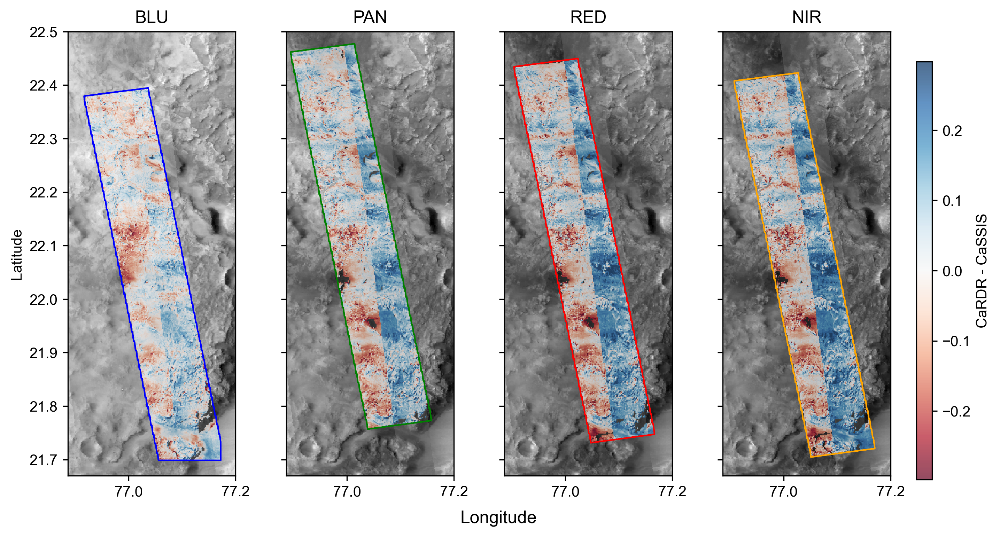

In [93]:
# 1% Stretch Colour Difference

fig, ax = plt.subplots(figsize=(10, 5), sharex=True, sharey=True, ncols=4, dpi=300)


# get the 1% percentiles for vmin and vmax
vmin, vmax = np.nanpercentile(diff_rgb, [1, 99])
vlim = max(abs(vmin), abs(vmax))
vmin, vmax = -vlim, vlim
# vmin, vmax = -200, 200

tile_subset.sel(band='BLU').plot(cmap='gray',ax=ax[0], rasterized=True)
diff_rgb.sel(band='BLU').plot(cmap='RdBu',ax=ax[0], vmin=vmin, vmax=vmax, rasterized=True, alpha=0.7)
ax[0].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='BLU'))
ax[0].plot(x, y, color='blue', linewidth=1)
ax[0].set_title('BLU')
ax[0].set_xlabel('') # drop x label
ax[0].set_ylabel('Latitude') # only show y label on the first plot
ax[0].collections[0].colorbar.remove()
ax[0].collections[1].colorbar.remove()

tile_subset.sel(band='PAN').plot(cmap='gray',ax=ax[1], rasterized=True)
diff_rgb.sel(band='PAN').plot(cmap='RdBu',ax=ax[1], vmin=vmin, vmax=vmax, rasterized=True, alpha=0.7)
ax[1].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='PAN'))
ax[1].plot(x, y, color='green', linewidth=1)
ax[1].set_title('PAN')
ax[1].set_xlabel('') # drop x label
ax[1].set_ylabel('') # only show y label on the first plot
ax[1].collections[0].colorbar.remove()
ax[1].collections[1].colorbar.remove()

tile_subset.sel(band='RED').plot(cmap='gray',ax=ax[2], rasterized=True)
diff_rgb.sel(band='RED').plot(cmap='RdBu',ax=ax[2], vmin=vmin, vmax=vmax, rasterized=True, alpha=0.7)
ax[2].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='RED'))
ax[2].plot(x, y, color='red', linewidth=1)
ax[2].set_title('RED')
ax[2].set_xlabel('') # drop x label
ax[2].set_ylabel('') # only show y label on the first plot
ax[2].collections[0].colorbar.remove()
ax[2].collections[1].colorbar.remove()

tile_subset.sel(band='NIR').plot(cmap='gray',ax=ax[3], rasterized=True, cbar_kwargs={'shrink': 0.9})
diff_rgb.sel(band='NIR').plot(cmap='RdBu',ax=ax[3], vmin=vmin, vmax=vmax, rasterized=True, alpha=0.7, cbar_kwargs={'shrink': 0.9})
ax[3].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='NIR'))
ax[3].plot(x, y, color='orange', linewidth=1)
ax[3].set_title('NIR')
ax[3].set_xlabel('') # drop x label
ax[3].set_ylabel('') # only show y label on the first plot
ax[3].collections[0].colorbar.remove()
ax[3].collections[1].colorbar.remove()

ax[0].set_ylim(bottom=21.67)
ax[0].set_xlim(right=77.2)

fig.supxlabel('Longitude')

fig.tight_layout(w_pad=0.0)

fig.subplots_adjust(right=0.92)

im = ax[0].collections[1]

# add colorbar in a manually-placed axes to the right of all subplots
cax = fig.add_axes([0.90, 0.1, 0.015, 0.8])
cbar = fig.colorbar(im, cax=cax, orientation='vertical')
cbar.set_label('CaRDR - CaSSIS')

# save the figure as a svg
out_file = out_dir / "cardr_cassis_col_comparison_diff.svg"
fig.savefig(out_file, format='svg', dpi=600)

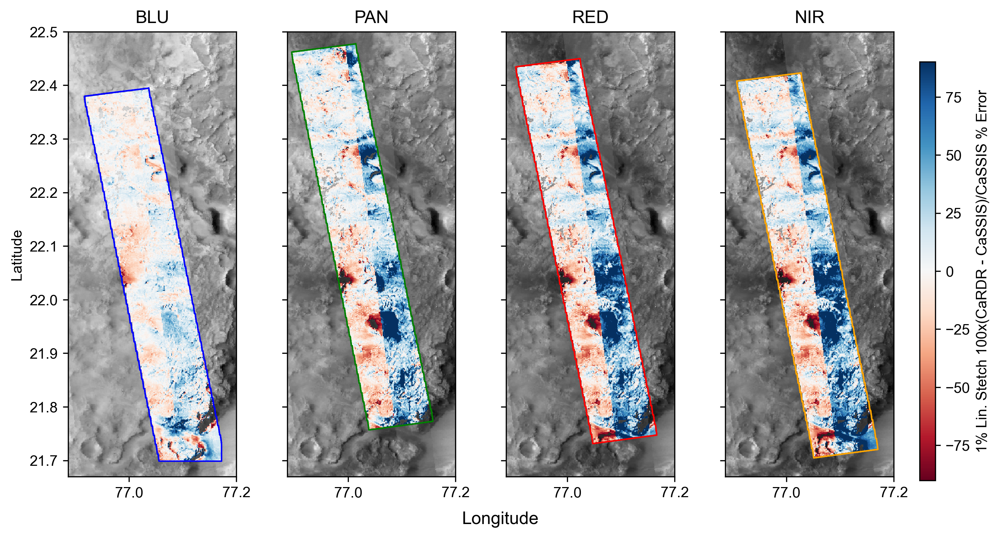

In [94]:
# 1% Stretch Colour Percentage Error

fig, ax = plt.subplots(figsize=(10, 5), sharex=True, sharey=True, ncols=4, dpi=300)


# get the 1% percentiles for vmin and vmax
vmin, vmax = np.nanpercentile(perr_rgb.sel(band='BLU'), [1, 99])
vlim = max(abs(vmin), abs(vmax))
vmin, vmax = -vlim, vlim
# vmin, vmax = -200, 200
 
tile_subset.sel(band='BLU').plot(cmap='gray',ax=ax[0], rasterized=True)
perr_rgb.sel(band='BLU').plot(cmap='RdBu',ax=ax[0], vmin=vmin, vmax=vmax, rasterized=True)
ax[0].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='BLU'))
ax[0].plot(x, y, color='blue', linewidth=1)
ax[0].set_title('BLU')
ax[0].set_xlabel('') # drop x label
ax[0].set_ylabel('Latitude') # only show y label on the first plot
ax[0].collections[0].colorbar.remove()
ax[0].collections[1].colorbar.remove()

tile_subset.sel(band='PAN').plot(cmap='gray',ax=ax[1], rasterized=True)
perr_rgb.sel(band='PAN').plot(cmap='RdBu',ax=ax[1], vmin=vmin, vmax=vmax, rasterized=True)
ax[1].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='PAN'))
ax[1].plot(x, y, color='green', linewidth=1)
ax[1].set_title('PAN')
ax[1].set_xlabel('') # drop x label
ax[1].set_ylabel('') # only show y label on the first plot
ax[1].collections[0].colorbar.remove()
ax[1].collections[1].colorbar.remove()

tile_subset.sel(band='RED').plot(cmap='gray',ax=ax[2], rasterized=True)
perr_rgb.sel(band='RED').plot(cmap='RdBu',ax=ax[2], vmin=vmin, vmax=vmax, rasterized=True)
ax[2].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='RED'))
ax[2].plot(x, y, color='red', linewidth=1)
ax[2].set_title('RED')
ax[2].set_xlabel('') # drop x label
ax[2].set_ylabel('') # only show y label on the first plot
ax[2].collections[0].colorbar.remove()
ax[2].collections[1].colorbar.remove()

tile_subset.sel(band='NIR').plot(cmap='gray',ax=ax[3], rasterized=True, cbar_kwargs={'shrink': 0.9})
perr_rgb.sel(band='NIR').plot(cmap='RdBu',ax=ax[3], vmin=vmin, vmax=vmax, rasterized=True, cbar_kwargs={'shrink': 0.9})
ax[3].set_aspect('equal', adjustable='box')
x,y = extract_footprint(shifted_da.sel(band='NIR'))
ax[3].plot(x, y, color='orange', linewidth=1)
ax[3].set_title('NIR')
ax[3].set_xlabel('') # drop x label
ax[3].set_ylabel('') # only show y label on the first plot
ax[3].collections[0].colorbar.remove()
ax[3].collections[1].colorbar.remove()

ax[0].set_ylim(bottom=21.67)
ax[0].set_xlim(right=77.2)

fig.supxlabel('Longitude')

fig.tight_layout(w_pad=0.0)

fig.subplots_adjust(right=0.92)

im = ax[0].collections[1]

# add colorbar in a manually-placed axes to the right of all subplots
cax = fig.add_axes([0.90, 0.1, 0.015, 0.8])
cbar = fig.colorbar(im, cax=cax, orientation='vertical')
cbar.set_label('1% Lin. Stetch 100x(CaRDR - CaSSIS)/CaSSIS % Error')

# save the figure as a svg
out_file = out_dir / "cardr_cassis_col_comparison_pcterr.svg"
fig.savefig(out_file, format='svg', dpi=600)

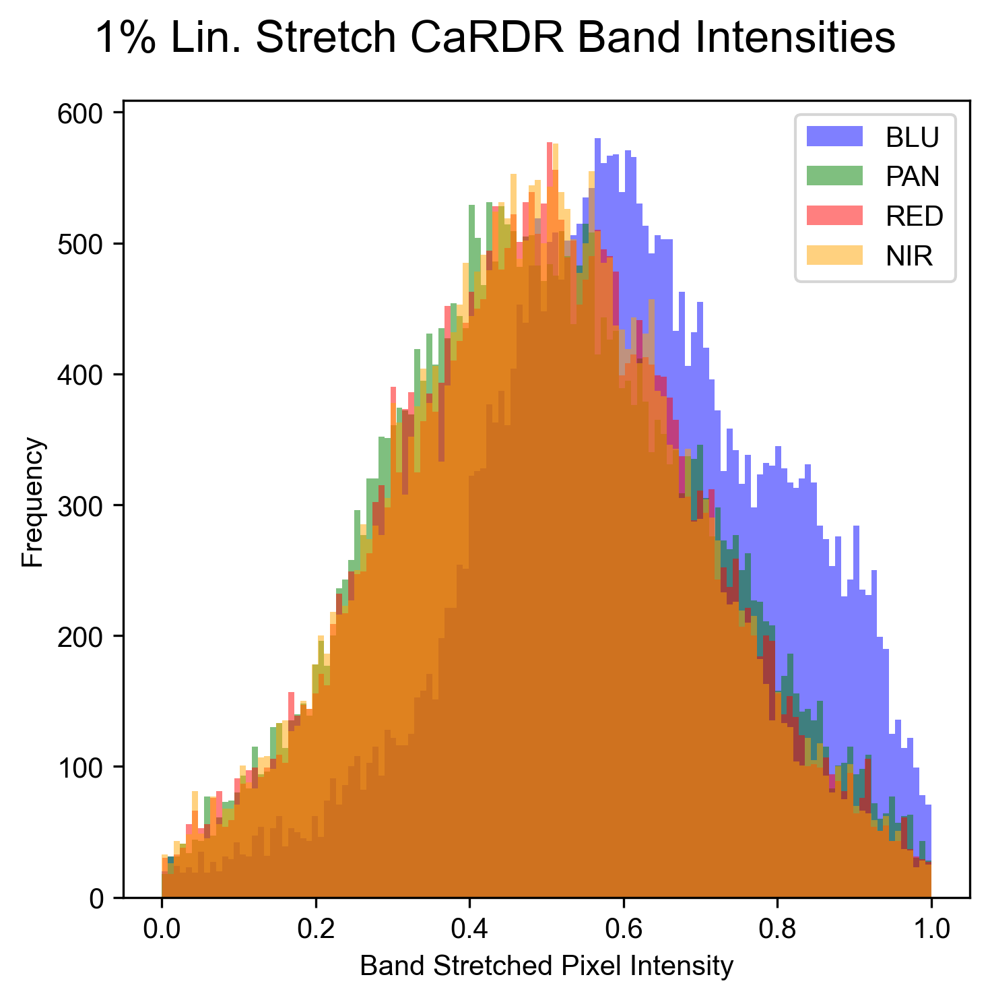

In [95]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

ax.hist(cardr_msk_str.sel(band='BLU').data[np.isfinite(cardr_msk_str.sel(band='BLU').data)].flatten(), bins=128, color='blue', alpha=0.5, label='BLU')
ax.hist(cardr_msk_str.sel(band='PAN').data[np.isfinite(cardr_msk_str.sel(band='PAN').data)].flatten(), bins=128, color='green', alpha=0.5, label='PAN')
ax.hist(cardr_msk_str.sel(band='RED').data[np.isfinite(cardr_msk_str.sel(band='RED').data)].flatten(), bins=128, color='red', alpha=0.5, label='RED')
ax.hist(cardr_msk_str.sel(band='NIR').data[np.isfinite(cardr_msk_str.sel(band='NIR').data)].flatten(), bins=128, color='orange', alpha=0.5, label='NIR')
# # clip xmin and xmax = ±20
# ax.set_xlim(1, 255)
# # y is frequency
ax.set_xlabel('Band Stretched Pixel Intensity')
ax.set_ylabel('Frequency')
fig.suptitle('1% Lin. Stretch CaRDR Band Intensities', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()

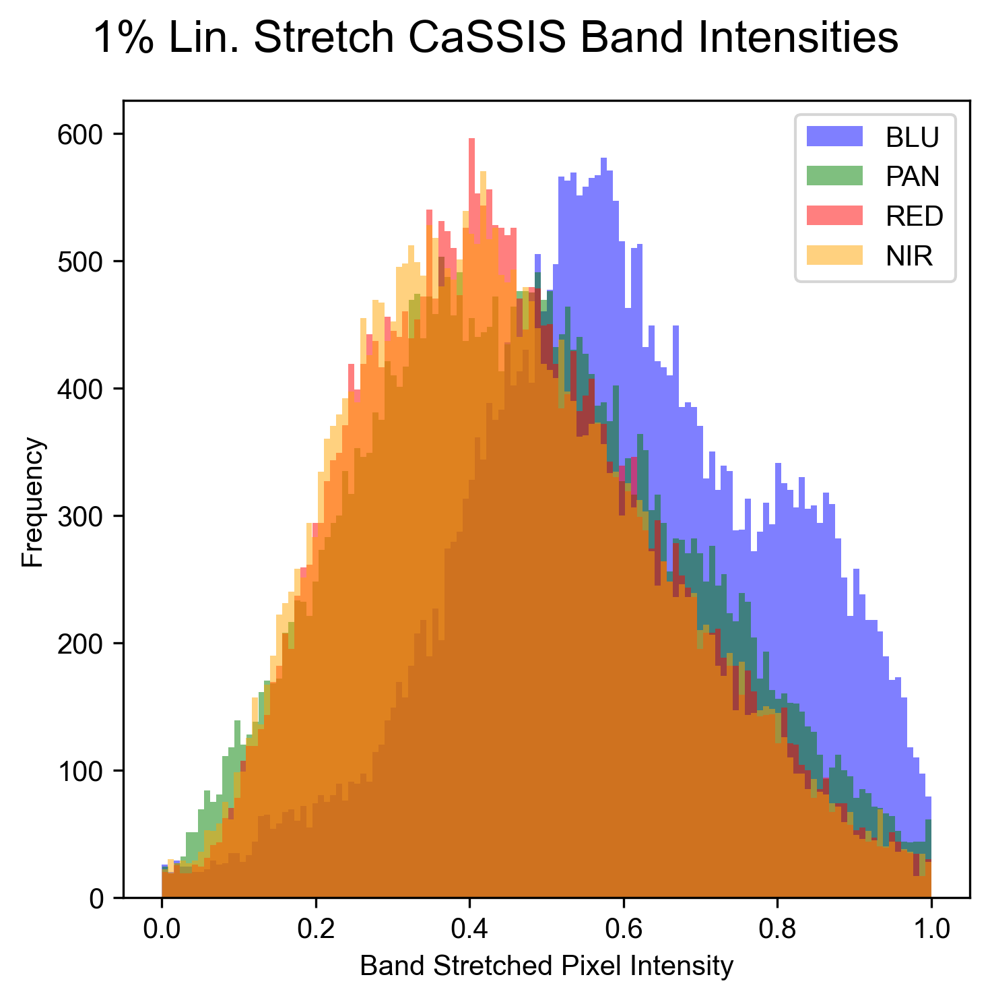

In [96]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

ax.hist(cassis_dwn_str.sel(band='BLU').data[np.isfinite(cassis_dwn_str.sel(band='BLU').data)].flatten(), bins=128, color='blue', alpha=0.5, label='BLU')
ax.hist(cassis_dwn_str.sel(band='PAN').data[np.isfinite(cassis_dwn_str.sel(band='PAN').data)].flatten(), bins=128, color='green', alpha=0.5, label='PAN')
ax.hist(cassis_dwn_str.sel(band='RED').data[np.isfinite(cassis_dwn_str.sel(band='RED').data)].flatten(), bins=128, color='red', alpha=0.5, label='RED')
ax.hist(cassis_dwn_str.sel(band='NIR').data[np.isfinite(cassis_dwn_str.sel(band='NIR').data)].flatten(), bins=128, color='orange', alpha=0.5, label='NIR')
# # clip xmin and xmax = ±20
# ax.set_xlim(-25, 25)
# # y is frequency
ax.set_xlabel('Band Stretched Pixel Intensity')
ax.set_ylabel('Frequency')
fig.suptitle('1% Lin. Stretch CaSSIS Band Intensities', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()

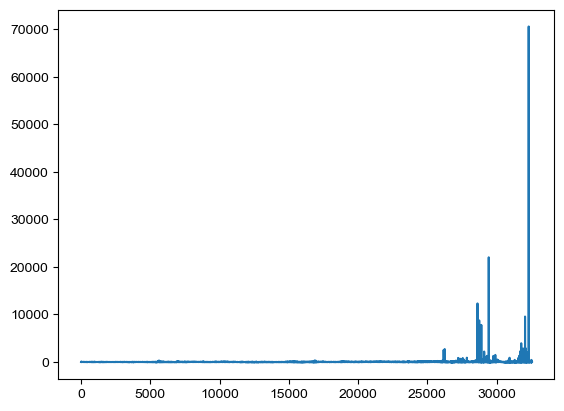

In [97]:
plt.plot(perr_rgb.sel(band='BLU').data[~np.isnan(perr_rgb.sel(band='BLU').data)].flatten())

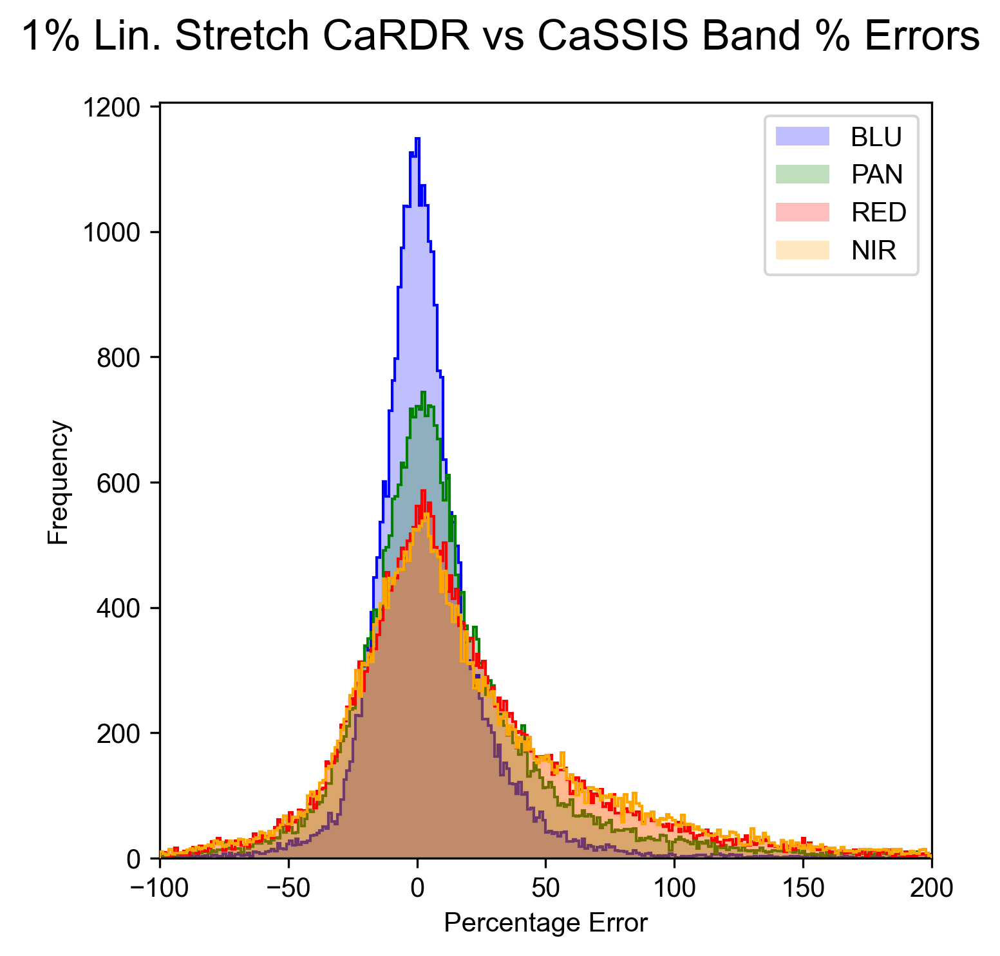

In [98]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

vmin, vmax = -100, 200

blu_hist = perr_rgb.sel(band='BLU').data[np.isfinite(perr_rgb.sel(band='BLU').data)].flatten() #.clip(vmin, vmax)
pan_hist = perr_rgb.sel(band='PAN').data[np.isfinite(perr_rgb.sel(band='PAN').data)].flatten() #.clip(vmin, vmax)
red_hist = perr_rgb.sel(band='RED').data[np.isfinite(perr_rgb.sel(band='RED').data)].flatten() #.clip(vmin, vmax)
nir_hist = perr_rgb.sel(band='NIR').data[np.isfinite(perr_rgb.sel(band='NIR').data)].flatten() #.clip(vmin, vmax)

histtype = 'stepfilled'

ax.hist(blu_hist, bins=256, color='blue', histtype='step', range=(vmin, vmax), zorder=0)
ax.hist(blu_hist, bins=256, color='blue', label='BLU', histtype='stepfilled', alpha=0.25, range=(vmin, vmax))

ax.hist(pan_hist, bins=256, color='green', histtype='step', range=(vmin, vmax), zorder=1)
ax.hist(pan_hist, bins=256, color='green', label='PAN', histtype='stepfilled', alpha=0.25, range=(vmin, vmax))        

ax.hist(red_hist, bins=256, color='red', histtype='step', range=(vmin, vmax), zorder=2)
ax.hist(red_hist, bins=256, color='red', label='RED', histtype='stepfilled', alpha=0.25, range=(vmin, vmax))

ax.hist(nir_hist, bins=256, color='orange', histtype='step', range=(vmin, vmax), zorder=3)
ax.hist(nir_hist, bins=256, color='orange', label='NIR', histtype='stepfilled', alpha=0.25, range=(vmin, vmax))

# clip xmin and xmax = ±20
ax.set_xlim(vmin, vmax)
# y is frequency
ax.set_xlabel('Percentage Error')
ax.set_ylabel('Frequency')
fig.suptitle('1% Lin. Stretch CaRDR vs CaSSIS Band % Errors', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()


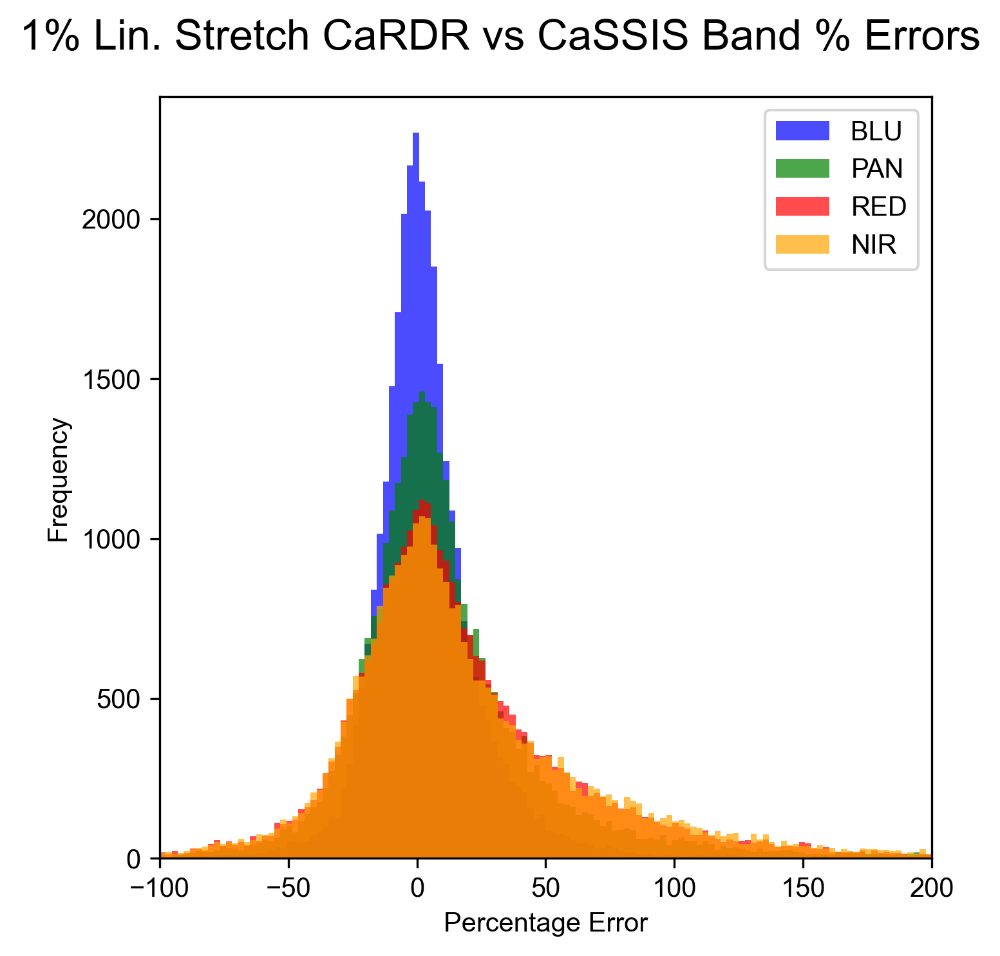

In [99]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

vmin, vmax = -100, 200

blu_hist = perr_rgb.sel(band='BLU').data[np.isfinite(perr_rgb.sel(band='BLU').data)].flatten() #.clip(vmin, vmax)
pan_hist = perr_rgb.sel(band='PAN').data[np.isfinite(perr_rgb.sel(band='PAN').data)].flatten() #.clip(vmin, vmax)
red_hist = perr_rgb.sel(band='RED').data[np.isfinite(perr_rgb.sel(band='RED').data)].flatten() #.clip(vmin, vmax)
nir_hist = perr_rgb.sel(band='NIR').data[np.isfinite(perr_rgb.sel(band='NIR').data)].flatten() #.clip(vmin, vmax)

histtype = 'stepfilled'

ax.hist(blu_hist, bins=128, color='blue', alpha=0.7, label='BLU', histtype=histtype, range=(vmin, vmax))
ax.hist(pan_hist, bins=128, color='green', alpha=0.7, label='PAN', histtype=histtype, range=(vmin, vmax))
ax.hist(red_hist, bins=128, color='red', alpha=0.7, label='RED', histtype=histtype, range=(vmin, vmax))
ax.hist(nir_hist, bins=128, color='orange', alpha=0.7, label='NIR', histtype=histtype, range=(vmin, vmax))
# clip xmin and xmax = ±20
ax.set_xlim(vmin, vmax)
# y is frequency
ax.set_xlabel('Percentage Error')
ax.set_ylabel('Frequency')
fig.suptitle('1% Lin. Stretch CaRDR vs CaSSIS Band % Errors', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()

# save the figure as a svg
out_file = out_dir / "cardr_cassis_col_hist_pcterr.svg"
fig.savefig(out_file, format='svg', dpi=600)

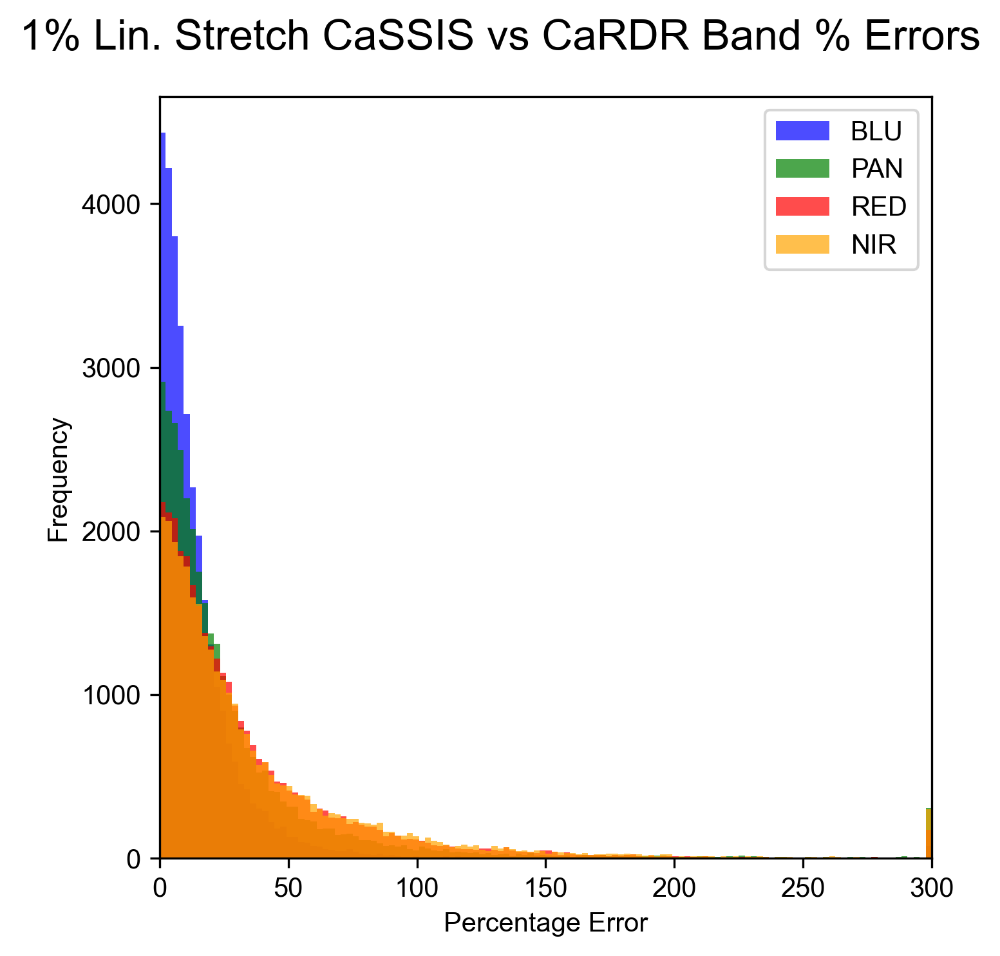

In [100]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

# vmin, vmax = -100, 500
vmin=0 
vmax = 300

blu_hist = np.abs(perr_rgb.sel(band='BLU').data[np.isfinite(perr_rgb.sel(band='BLU').data)]).flatten().clip(vmin, vmax)
pan_hist = np.abs(perr_rgb.sel(band='PAN').data[np.isfinite(perr_rgb.sel(band='PAN').data)]).flatten().clip(vmin, vmax)
red_hist = np.abs(perr_rgb.sel(band='RED').data[np.isfinite(perr_rgb.sel(band='RED').data)]).flatten().clip(vmin, vmax)
nir_hist = np.abs(perr_rgb.sel(band='NIR').data[np.isfinite(perr_rgb.sel(band='NIR').data)]).flatten().clip(vmin, vmax)

ax.hist(blu_hist, bins=128, color='blue', alpha=0.7, label='BLU')
ax.hist(pan_hist, bins=128, color='green', alpha=0.7, label='PAN')
ax.hist(red_hist, bins=128, color='red', alpha=0.7, label='RED')
ax.hist(nir_hist, bins=128, color='orange', alpha=0.7, label='NIR')
# clip xmin and xmax = ±20
# log x
# ax.set_xscale('log')
ax.set_xlim(vmin, vmax)
# y is frequency
ax.set_xlabel('Percentage Error')
ax.set_ylabel('Frequency')
fig.suptitle('1% Lin. Stretch CaSSIS vs CaRDR Band % Errors', fontsize=16)
fig.tight_layout(w_pad=0.0)
ax.legend()

Bi-variate plot - cassis value vs per err

Text(0, 0.5, 'CaSSIS Band Stretched Intensity')

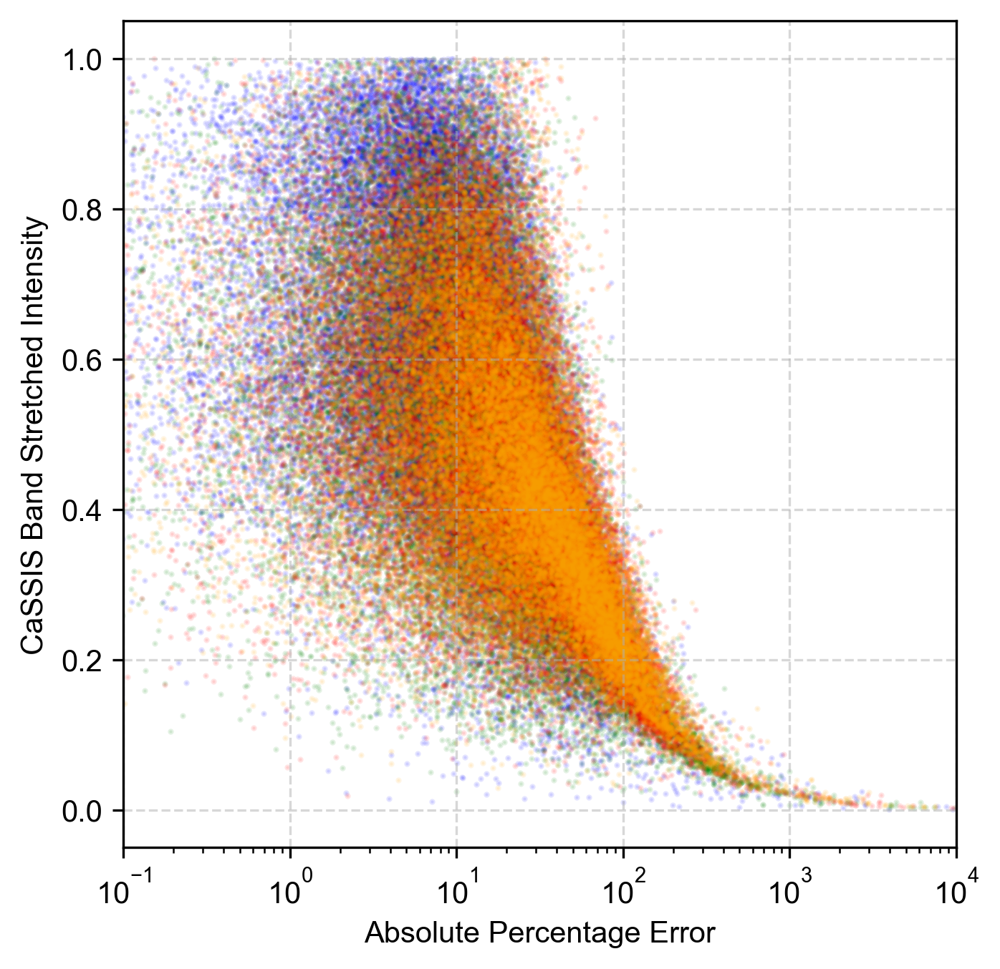

In [101]:
# plot the histrogram of blu err, pan err, etc. on one histogra, with each in a different colour
fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

# make a 2D density plot of BLU val vs BLU percentage error
blu_vals = cassis_dwn_str.sel(band='BLU').data[np.isfinite(cardr_msk_str.sel(band='BLU').data)].flatten()
blu_errs = np.abs(perr_rgb.sel(band='BLU').data[np.isfinite(cardr_msk_str.sel(band='BLU').data)].flatten())

# pan
pan_vals = cassis_dwn_str.sel(band='PAN').data[np.isfinite(cardr_msk_str.sel(band='PAN').data)].flatten()
pan_errs = np.abs(perr_rgb.sel(band='PAN').data[np.isfinite(cardr_msk_str.sel(band='PAN').data)].flatten())

# red
red_vals = cassis_dwn_str.sel(band='RED').data[np.isfinite(cardr_msk_str.sel(band='RED').data)].flatten()
red_errs = np.abs(perr_rgb.sel(band='RED').data[np.isfinite(cardr_msk_str.sel(band='RED').data)].flatten())

# nir
nir_vals = cassis_dwn_str.sel(band='NIR').data[np.isfinite(cardr_msk_str.sel(band='NIR').data)].flatten()
nir_errs = np.abs(perr_rgb.sel(band='NIR').data[np.isfinite(cardr_msk_str.sel(band='NIR').data)].flatten())

# density plot
ax.scatter(blu_errs, blu_vals, color='blue', alpha=0.1, label='BLU', s=1)
ax.scatter(pan_errs, pan_vals, color='green', alpha=0.1, label='PAN', s=1)
ax.scatter(red_errs, red_vals, color='red', alpha=0.1, label='RED', s=1)
ax.scatter(nir_errs, nir_vals, color='orange', alpha=0.1, label='NIR', s=1)
# x min is 0.1
ax.set_xlim(0.1, 10000)
ax.set_xscale('log')
ax.tick_params(axis='y', which='minor') 

# logarithmic x scale grid
ax.grid(which='major', linestyle='--', alpha=0.5)
# x albel is percentage error
ax.set_xlabel('Absolute Percentage Error')
ax.set_ylabel('CaSSIS Band Stretched Intensity')

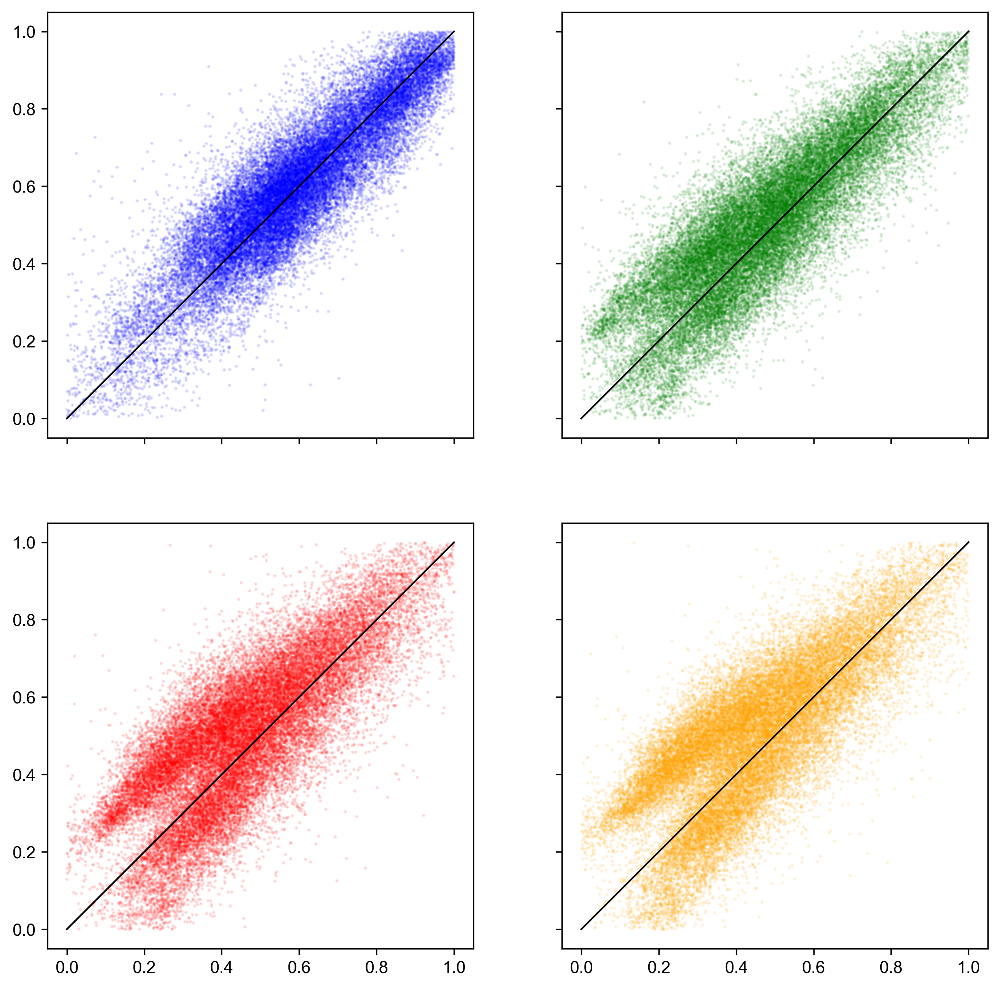

In [102]:
# let plot cardr_str vs cassis_str on line plots
fig, ax = plt.subplots(figsize=(10, 10), sharex=True, sharey=True, ncols=2, nrows=2, dpi=300)

cardr_blu_vals = cardr_msk_str.sel(band='BLU').data[np.isfinite(cardr_msk_str.sel(band='BLU').data)].flatten()
cassis_blu_vals = cassis_dwn_str.sel(band='BLU').data[np.isfinite(cardr_msk_str.sel(band='BLU').data)].flatten()
ax[0][0].scatter(cassis_blu_vals, cardr_blu_vals, color='blue', alpha=0.1, label='BLU', s=1)
# plot line of concordance
ax[0][0].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[0][0].set_aspect('equal', adjustable='box')

cardr_pan_vals = cardr_msk_str.sel(band='PAN').data[np.isfinite(cardr_msk_str.sel(band='PAN').data)].flatten()
cassis_pan_vals = cassis_dwn_str.sel(band='PAN').data[np.isfinite(cardr_msk_str.sel(band='PAN').data)].flatten()
ax[0][1].scatter(cassis_pan_vals, cardr_pan_vals, color='green', alpha=0.1, label='PAN', s=1)
# plot line of concordance
ax[0][1].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[0][1].set_aspect('equal', adjustable='box')

cardr_red_vals = cardr_msk_str.sel(band='RED').data[np.isfinite(cardr_msk_str.sel(band='RED').data)].flatten()
cassis_red_vals = cassis_dwn_str.sel(band='RED').data[np.isfinite(cardr_msk_str.sel(band='RED').data)].flatten()
ax[1][0].scatter(cassis_red_vals, cardr_red_vals, color='red', alpha=0.1, label='RED', s=1)
# plot line of concordance
ax[1][0].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[1][0].set_aspect('equal', adjustable='box')  

cardr_nir_vals = cardr_msk_str.sel(band='NIR').data[np.isfinite(cardr_msk_str.sel(band='NIR').data)].flatten()
cassis_nir_vals = cassis_dwn_str.sel(band='NIR').data[np.isfinite(cardr_msk_str.sel(band='NIR').data)].flatten()
ax[1][1].scatter(cassis_nir_vals, cardr_nir_vals, color='orange', alpha=0.1, label='NIR', s=1)
# plot line of concordance
ax[1][1].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[1][1].set_aspect('equal', adjustable='box')


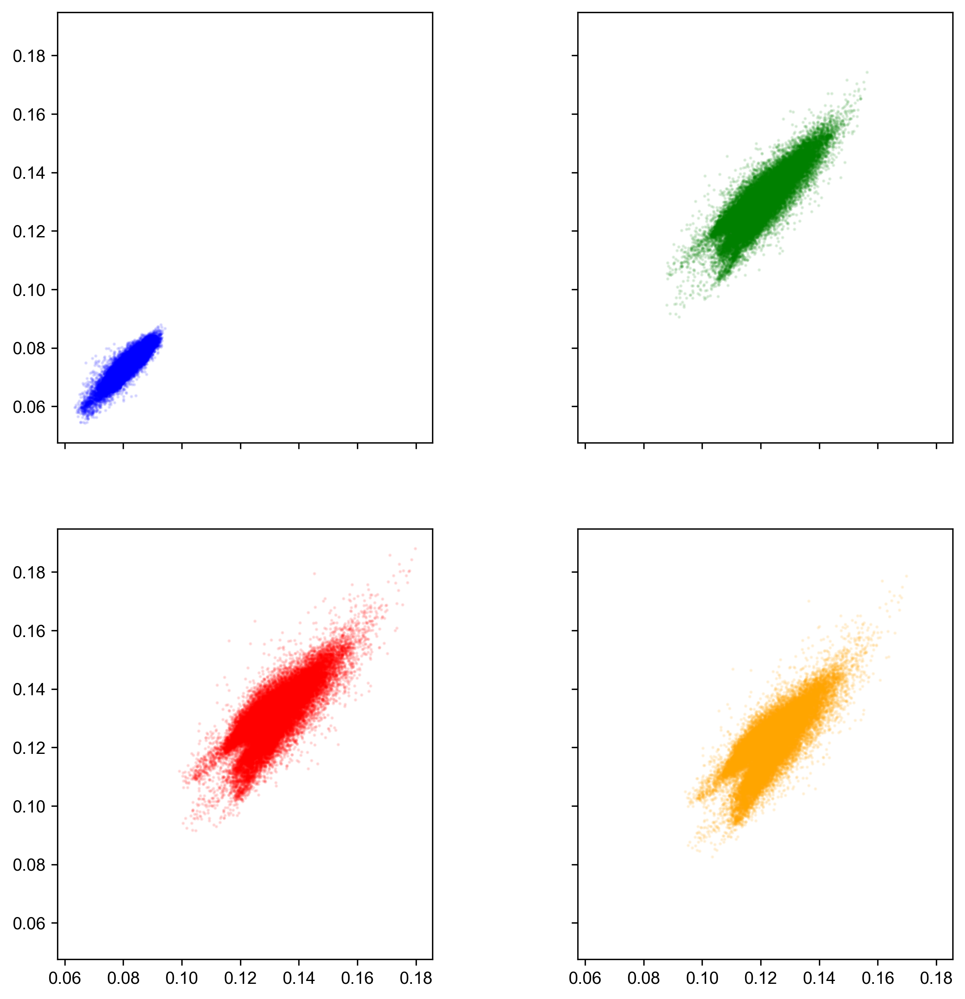

In [103]:
# let plot cardr la vs cassis la on line plots
fig, ax = plt.subplots(figsize=(10, 10), sharex=True, sharey=True, ncols=2, nrows=2, dpi=300)

cardr_blu_vals = masked_tile_subset.sel(band='BLU').data[np.isfinite(cassis_dwn.sel(band='BLU').data)].flatten()
cassis_blu_vals = cassis_dwn.sel(band='BLU').data[np.isfinite(cassis_dwn.sel(band='BLU').data)].flatten()
ax[0][0].scatter(cassis_blu_vals, cardr_blu_vals, color='blue', alpha=0.1, label='BLU', s=1)
# plot line of concordance
# ax[0][0].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[0][0].set_aspect('equal', adjustable='box')

cardr_pan_vals = masked_tile_subset.sel(band='PAN').data[np.isfinite(cassis_dwn.sel(band='PAN').data)].flatten()
cassis_pan_vals = cassis_dwn.sel(band='PAN').data[np.isfinite(cassis_dwn.sel(band='PAN').data)].flatten()
ax[0][1].scatter(cassis_pan_vals, cardr_pan_vals, color='green', alpha=0.1, label='PAN', s=1)
# plot line of concordance
# ax[0][1].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[0][1].set_aspect('equal', adjustable='box')

cardr_red_vals = masked_tile_subset.sel(band='RED').data[np.isfinite(cassis_dwn.sel(band='RED').data)].flatten()
cassis_red_vals = cassis_dwn.sel(band='RED').data[np.isfinite(cassis_dwn.sel(band='RED').data)].flatten()
ax[1][0].scatter(cassis_red_vals, cardr_red_vals, color='red', alpha=0.1, label='RED', s=1)
# plot line of concordance
# ax[1][0].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[1][0].set_aspect('equal', adjustable='box')  

cardr_nir_vals = masked_tile_subset.sel(band='NIR').data[np.isfinite(cassis_dwn.sel(band='NIR').data)].flatten()
cassis_nir_vals = cassis_dwn.sel(band='NIR').data[np.isfinite(cassis_dwn.sel(band='NIR').data)].flatten()
ax[1][1].scatter(cassis_nir_vals, cardr_nir_vals, color='orange', alpha=0.1, label='NIR', s=1)
# plot line of concordance
# ax[1][1].plot([0, 1], [0, 1], color='black', linewidth=1)
ax[1][1].set_aspect('equal', adjustable='box')


# Statistics on the errors

Remember: perr_la = 100 * (CaRDR - CaSSIS) / CaSSIS

so +ve means CaRDR overestimates, -ve means it underestimates

Error in each channel, LA comparison

In [104]:
blu_err_mean = perr_la.sel(band='BLU').mean()
pan_err_mean = perr_la.sel(band='PAN').mean()
red_err_mean = perr_la.sel(band='RED').mean()
nir_err_mean = perr_la.sel(band='NIR').mean()

print(f"Mean LA Percentage Error - BLU: {blu_err_mean:.2f}%")
print(f"Mean LA Percentage Error - PAN: {pan_err_mean:.2f}%")
print(f"Mean LA Percentage Error - RED: {red_err_mean:.2f}%")
print(f"Mean LA Percentage Error - NIR: {nir_err_mean:.2f}%")

Mean LA Percentage Error - BLU: -8.92%
Mean LA Percentage Error - PAN: 8.14%
Mean LA Percentage Error - RED: -0.61%
Mean LA Percentage Error - NIR: -1.70%


In [105]:
# standard deviation
blu_err_std = perr_la.sel(band='BLU').std()
pan_err_std = perr_la.sel(band='PAN').std()
red_err_std = perr_la.sel(band='RED').std()
nir_err_std = perr_la.sel(band='NIR').std()

print(f"Standard Deviation of LA Percentage Error - BLU: {blu_err_std:.2f}%")
print(f"Standard Deviation of LA Percentage Error - PAN: {pan_err_std:.2f}%")
print(f"Standard Deviation of LA Percentage Error - RED: {red_err_std:.2f}%")
print(f"Standard Deviation of LA Percentage Error - NIR: {nir_err_std:.2f}%")

Standard Deviation of LA Percentage Error - BLU: 2.44%
Standard Deviation of LA Percentage Error - PAN: 4.28%
Standard Deviation of LA Percentage Error - RED: 4.88%
Standard Deviation of LA Percentage Error - NIR: 5.27%


In [106]:
perr_la.mean()

<xarray.DataArray ()> Size: 8B
array(-0.72188236)
Coordinates:
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    WAVELENGTH:     500.0nm
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      Lambert Albedo
    units:          
    _FillValue:     nan

In [107]:
# get the max histogram value for each band, for an 128 bin histogram
blu_hist = perr_la.sel(band='BLU').data[np.isfinite(perr_la.sel(band='BLU').data)].flatten() #.clip(vmin, vmax)
pan_hist = perr_la.sel(band='PAN').data[np.isfinite(perr_la.sel(band='PAN').data)].flatten() #.clip(vmin, vmax)
red_hist = perr_la.sel(band='RED').data[np.isfinite(perr_la.sel(band='RED').data)].flatten() #.clip(vmin, vmax)
nir_hist = perr_la.sel(band='NIR').data[np.isfinite(perr_la.sel(band='NIR').data)].flatten() #.clip(vmin, vmax)

blu_hist_vals, blu_hist_edges = np.histogram(blu_hist, bins=128)
pan_hist_vals, pan_hist_edges = np.histogram(pan_hist, bins=128)
red_hist_vals, red_hist_edges = np.histogram(red_hist, bins=128)
nir_hist_vals, nir_hist_edges = np.histogram(nir_hist, bins=128)

# get the max histogram bin for the max histogram value for each band
blu_hist_max_bin = blu_hist_edges[np.argmax(blu_hist_vals)]
pan_hist_max_bin = pan_hist_edges[np.argmax(pan_hist_vals)]
red_hist_max_bin = red_hist_edges[np.argmax(red_hist_vals)]
nir_hist_max_bin = nir_hist_edges[np.argmax(nir_hist_vals)]

print(f"Max histogram bin - BLU: {blu_hist_max_bin:.2f}%")
print(f"Max histogram bin - PAN: {pan_hist_max_bin:.2f}%")
print(f"Max histogram bin - RED: {red_hist_max_bin:.2f}%")  
print(f"Max histogram bin - NIR: {nir_hist_max_bin:.2f}%")

Max histogram bin - BLU: -9.04%
Max histogram bin - PAN: 6.65%
Max histogram bin - RED: 2.02%
Max histogram bin - NIR: 1.90%


In [108]:
blu_err_mean = perr_rgb.sel(band='BLU').mean()
pan_err_mean = perr_rgb.sel(band='PAN').mean()
red_err_mean = perr_rgb.sel(band='RED').mean()
nir_err_mean = perr_rgb.sel(band='NIR').mean()

print(f"Mean Stretch Percentage Error - BLU: {blu_err_mean:.2f}%")
print(f"Mean Stretch Percentage Error - PAN: {pan_err_mean:.2f}%")
print(f"Mean Stretch Percentage Error - RED: {red_err_mean:.2f}%")
print(f"Mean Stretch Percentage Error - NIR: {nir_err_mean:.2f}%")

Mean Stretch Percentage Error - BLU: 9.95%
Mean Stretch Percentage Error - PAN: 23.51%
Mean Stretch Percentage Error - RED: 29.68%
Mean Stretch Percentage Error - NIR: 210.35%


In [109]:
# standard deviations
blu_err_std = perr_rgb.sel(band='BLU').std()
pan_err_std = perr_rgb.sel(band='PAN').std()
red_err_std = perr_rgb.sel(band='RED').std()
nir_err_std = perr_rgb.sel(band='NIR').std()
print(f"Standard Deviation of Stretch Percentage Error - BLU: {blu_err_std:.2f}%")
print(f"Standard Deviation of Stretch Percentage Error - PAN: {pan_err_std:.2f}%")
print(f"Standard Deviation of Stretch Percentage Error - RED: {red_err_std:.2f}%")
print(f"Standard Deviation of Stretch Percentage Error - NIR: {nir_err_std:.2f}%")

Standard Deviation of Stretch Percentage Error - BLU: 428.06%
Standard Deviation of Stretch Percentage Error - PAN: 385.78%
Standard Deviation of Stretch Percentage Error - RED: 590.35%
Standard Deviation of Stretch Percentage Error - NIR: 32495.11%


In [110]:
# get the max histogram value for each band, for an 128 bin histogram
blu_hist = perr_rgb.sel(band='BLU').data[np.isfinite(perr_rgb.sel(band='BLU').data)].flatten() #.clip(vmin, vmax)
pan_hist = perr_rgb.sel(band='PAN').data[np.isfinite(perr_rgb.sel(band='PAN').data)].flatten() #.clip(vmin, vmax)
red_hist = perr_rgb.sel(band='RED').data[np.isfinite(perr_rgb.sel(band='RED').data)].flatten() #.clip(vmin, vmax)
nir_hist = perr_rgb.sel(band='NIR').data[np.isfinite(perr_rgb.sel(band='NIR').data)].flatten() #.clip(vmin, vmax)

blu_hist_vals, blu_hist_edges = np.histogram(blu_hist, bins=128, range=(vmin, vmax))
pan_hist_vals, pan_hist_edges = np.histogram(pan_hist, bins=128, range=(vmin, vmax))
red_hist_vals, red_hist_edges = np.histogram(red_hist, bins=128, range=(vmin, vmax))
nir_hist_vals, nir_hist_edges = np.histogram(nir_hist, bins=128, range=(vmin, vmax))

# get the max histogram bin for the max histogram value for each band
blu_hist_max_bin = blu_hist_edges[np.argmax(blu_hist_vals)]
pan_hist_max_bin = pan_hist_edges[np.argmax(pan_hist_vals)]
red_hist_max_bin = red_hist_edges[np.argmax(red_hist_vals)]
nir_hist_max_bin = nir_hist_edges[np.argmax(nir_hist_vals)]

print(f"Max histogram bin - BLU: {blu_hist_max_bin:.2f}%")
print(f"Max histogram bin - PAN: {pan_hist_max_bin:.2f}%")
print(f"Max histogram bin - RED: {red_hist_max_bin:.2f}%")  
print(f"Max histogram bin - NIR: {nir_hist_max_bin:.2f}%")

Max histogram bin - BLU: 0.00%
Max histogram bin - PAN: 0.00%
Max histogram bin - RED: 2.34%
Max histogram bin - NIR: 2.34%


In [111]:
perr_rgb.mean()

<xarray.DataArray ()> Size: 8B
array(68.18528843)
Coordinates:
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    WAVELENGTH:     500.0nm
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      Lambert Albedo
    units:          
    _FillValue:     nan

In [112]:
np.percentile(np.abs(blu_hist), 50)

np.float64(9.840101481011455)